<a href="https://colab.research.google.com/github/samyyy2311/Unsupervised_Learning/blob/main/Unsupervised_Learning.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Assignment - Customer Segmentation using Unsupervised Learning

**Dataset:** Online Retail II - [UCI Machine Learning Repository](https://archive.ics.uci.edu/dataset/502/online+retail+ii)

**Source:** Chen, D. (2012). Online Retail II [Dataset]. UCI Machine Learning Repository.

**Author:** Samarth Lad - 2025EB1100248

# Task A: Problem Framing and Data Understanding

## Step 1: Loading the Dataset

**Why:** Before I do anything else, I need to get the raw data into Python and see its basic size and structure. I'm downloading it straight from the UCI page so the notebook can run from start to finish without needing anyone to manually upload a file. The original file stays untouched in the raw folder.

**What the code does:** Sets up the libraries and a random seed, downloads and unzips the data from UCI, reads both sheets (2009-2010 and 2010-2011), joins them into one table called df, and shows the first 5 rows.

In [1]:
import pandas as pd
import numpy as np
import urllib.request, zipfile, io

# setting a seed so results don't change every time I rerun the notebook
RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)

In [2]:
# Downloading the raw data from uci, the original file is saved untouched in the raw folder
url = 'https://archive.ics.uci.edu/static/public/502/online+retail+ii.zip'
zipfile.ZipFile(io.BytesIO(urllib.request.urlopen(url).read())).extractall('raw')

# Reading both sheets (2009-2010 and 2010-2011) and joining them into one table
sheets = pd.read_excel('raw/online_retail_II.xlsx', sheet_name=None)
df = pd.concat(sheets.values(), ignore_index=True)
df.head()

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom


### What I found

- The two sheets together have **1,067,371 rows** and **8 columns** (525,461 + 541,910)
- The columns are `Invoice`, `StockCode`, `Description`, `Quantity`, `InvoiceDate`, `Price`, `Customer ID` and `Country`
- Each row is one product line on an invoice, not one customer, so I will have to group rows into customers before clustering

## Step 2a: Checking Data Types and Date Range

**Why:** Before I clean anything, I want to know what type each column is stored as and what time period the data covers. Wrong types (like dates stored as text) would cause problems later when I build features like recency.

**What the code does:** Shows each column name, how many non-null values it has and its data type, then shows the first and last invoice date.

In [3]:
df.info()
df['InvoiceDate'].agg(['min', 'max'])

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1067371 entries, 0 to 1067370
Data columns (total 8 columns):
 #   Column       Non-Null Count    Dtype         
---  ------       --------------    -----         
 0   Invoice      1067371 non-null  object        
 1   StockCode    1067371 non-null  object        
 2   Description  1062989 non-null  object        
 3   Quantity     1067371 non-null  int64         
 4   InvoiceDate  1067371 non-null  datetime64[ns]
 5   Price        1067371 non-null  float64       
 6   Customer ID  824364 non-null   float64       
 7   Country      1067371 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(1), object(4)
memory usage: 65.1+ MB


,InvoiceDate
min,2009-12-01 07:45:00
max,2011-12-09 12:50:00


### What I found

- `InvoiceDate` was read as a proper date, so I don't need to convert it
- The data runs from **1 December 2009 to 9 December 2011**, about two years of orders
- `Invoice` is stored as text, because cancellation invoices start with the letter C
- `Customer ID` is stored as a decimal number, which usually means some values are missing, so I'll check that next

## Step 2b: Checking Missing Values

**Why:** Missing values can't be used in distance calculations. Customer ID matters most here, because it decides which rows I can group into customers.

**What the code does:** Counts how many values are missing in each column.

In [4]:
df.isna().sum()

,0
Invoice,0
StockCode,0
Description,4382
Quantity,0
InvoiceDate,0
Price,0
Customer ID,243007
Country,0


### What I found

- **243,007 rows (22.8%) have no Customer ID**, so I can't link them to any customer. This is the biggest data problem for building a customer-level table
- `Description` is missing in 4,382 rows (0.4%), which doesn't matter much since I won't cluster on product text
- No other column has missing values
- I will decide what to do with the rows without a Customer ID in Task B

## Step 2c: Checking Duplicate Rows

**Why:** Duplicate lines would count the same purchase twice and make a customer look like they spent more than they did.

**What the code does:** Counts the rows that are exact copies of another row.

In [5]:
df.duplicated().sum()

np.int64(34335)

### What I found

- There are **34,335 fully duplicated rows (3.2%)**
- Some of these may be real repeat scans of the same item on one invoice, so I'll look at them more closely before deciding to remove them

## Step 2d: Counting Customers, Invoices, Products and Countries

**Why:** The assignment wants one row per customer, so I need to know how many customers there are compared to invoices and products. I also want to see how the countries are spread, in case one country dominates.

**What the code does:** Counts the unique values in four columns, then shows the five countries with the most rows.

In [6]:
print(df[['Customer ID', 'Invoice', 'StockCode', 'Country']].nunique())
print()
print(df['Country'].value_counts().head(5))

Customer ID     5942
Invoice        53628
StockCode       5305
Country           43
dtype: int64

Country
United Kingdom    981330
EIRE               17866
Germany            17624
France             14330
Netherlands         5140
Name: count, dtype: int64


### What I found

- There are **5,942 unique customers**, 53,628 invoices, 5,305 products and 43 countries
- That is about 139 rows per customer on average (824,364 rows with an ID divided by 5,942 customers), so summarising each customer into a few features will be a big reduction
- The United Kingdom has 981,330 rows, which is **91.9%** of the whole dataset. The next largest are EIRE (17,866), Germany (17,624), France (14,330) and the Netherlands (5,140)
- Because the data is mostly one country, I'll be careful about using `Country` as a clustering feature

## Step 2e: Checking Cancellations and Zero or Negative Values

**Why:** Cancellations and refunds are not purchases, and the assignment asks me to explain how I treat them. Zero or negative prices and quantities also need a closer look.

**What the code does:** Prints three counts in order: invoices that start with C (cancellations), rows with a Quantity of 0 or less, and rows with a Price of 0 or less.

In [7]:
# Cancellations start with the letter C
inv = df['Invoice'].astype(str)
print('Cancellations:', inv.str.startswith('C').sum())
print('Quantity <= 0:', (df['Quantity'] <= 0).sum())
print('Price <= 0:', (df['Price'] <= 0).sum())

Cancellations: 19494
Quantity <= 0: 22950
Price <= 0: 6207


### What I found

- **19,494 rows (1.8%)** are cancellations
- **22,950 rows (2.2%)** have a Quantity of 0 or less, which is more than the number of cancellations, so some negative quantities are not cancellations. I'll check what they are in Step 3b
- **6,207 rows (0.6%)** have a Price of 0 or less

In [8]:
df[['Quantity', 'Price']].describe(percentiles=[.01, .99]).round(2)

,Quantity,Price
count,1067371.00,1067371.00
mean,9.94,4.65
std,172.71,123.55
min,-80995.00,-53594.36
1%,-3.00,0.21
50%,3.00,2.10
99%,100.00,18.00
max,80995.00,38970.00


### What I found

- `Quantity` has a median of 3 and a mean of about 9.9, but the maximum is 80,995 and the minimum is -80,995. The 1st and 99th percentiles are only -3 and 100
- `Price` has a median of 2.10 and a mean of about 4.65, but the maximum is 38,970 and the minimum is -53,594.36, which is clearly not a normal sale
- Both columns are very skewed, with a few extreme rows far from everything else. I'll need to handle these later, for example with a log transform or robust scaling

## Step 3a: Odd Invoice Numbers

**Why:** Normal invoice numbers are digits only, or digits with a C in front for cancellations. Anything else could be an adjustment or a non-sale entry, so I want to see if any invoices don't follow that pattern.

**What the code does:** Shows the rows whose invoice number doesn't match either pattern.

In [9]:
# Showing the invoices that don't follow the normal pattern
df[~inv.str.match(r'^C?\d+$')]

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
179403,A506401,B,Adjust bad debt,1,2010-04-29 13:36:00,-53594.36,NaN,United Kingdom
276274,A516228,B,Adjust bad debt,1,2010-07-19 11:24:00,-44031.79,NaN,United Kingdom
403472,A528059,B,Adjust bad debt,1,2010-10-20 12:04:00,-38925.87,NaN,United Kingdom
825443,A563185,B,Adjust bad debt,1,2011-08-12 14:50:00,11062.06,NaN,United Kingdom
825444,A563186,B,Adjust bad debt,1,2011-08-12 14:51:00,-11062.06,NaN,United Kingdom
825445,A563187,B,Adjust bad debt,1,2011-08-12 14:52:00,-11062.06,NaN,United Kingdom


### What I found

- Six invoices don't follow the normal pattern. All of them have stock code `B`, the description "Adjust bad debt", a Quantity of 1, no Customer ID, and are from the United Kingdom
- These are accounting entries, not sales. Their prices are -53,594.36, -44,031.79, -38,925.87, 11,062.06 and -11,062.06 (twice)
- The extreme minimum Price I saw in Step 2f comes from these rows. I will remove them

## Step 3b: Negative Quantity That Isn't a Cancellation

**Why:** There are more rows with a Quantity of 0 or less (22,950) than cancellations (19,494), so some of them must be something else.

**What the code does:** Counts the negative-quantity rows that are not cancellations, then how many of those have a Price of 0 and how many have no Customer ID.

In [10]:
# Negative quantity rows that are not cancellations
neg_not_c = df[(df['Quantity'] <= 0) & (~inv.str.startswith('C'))]
print('Rows:', len(neg_not_c))
print('With price 0:', neg_not_c['Price'].eq(0).sum())
print('With no customer id:', neg_not_c['Customer ID'].isna().sum())

Rows: 3457
With price 0: 3457
With no customer id: 3457


### What I found

- Six invoices don't follow the normal pattern. All of them have stock code `B`, the description "Adjust bad debt", a Quantity of 1, no Customer ID, and are from the United Kingdom
- These are accounting entries, not sales. Their prices are -53,594.36, -44,031.79, -38,925.87, 11,062.06 and -11,062.06 (twice)
- The extreme minimum Price I saw in Step 2f comes from these rows. I will remove them

## Step 3c: Zero Price Rows

**Why:** A price of 0 isn't a normal sale, so I want to know how many there are and whether they belong to real customers.

**What the code does:** Counts the zero-price rows, then how many of them have no Customer ID.

In [11]:
# Rows where the price is zero
zero_price = df[df['Price'] == 0]
print('Zero price rows:', len(zero_price))
print('With no customer id:', zero_price['Customer ID'].isna().sum())

Zero price rows: 6202
With no customer id: 6131


### What I found

- **6,202 rows** have a Price of exactly 0, and 6,131 of them have no Customer ID. The other 71 do have one
- Adding the 5 negative prices from Step 3a gives 6,207, which is exactly the number of rows with a Price of 0 or less in Step 2e
- A zero-price row has no spending to measure, so I plan to remove all of them

## Step 3d: Stock Codes That Aren't Products

**Why:** Some stock codes with no digits are usually fees, postage or adjustments, not things a customer actually bought. Keeping them would give a wrong picture of buying behaviour.

**What the code does:** Lists every stock code that contains no digits, with how many rows each one has.

In [12]:
# Stock codes with no digits are usually fees or postage, not real products
sc = df['StockCode'].astype(str)
df[~sc.str.contains(r'\d')]['StockCode'].value_counts()

,count
StockCode,
POST,2122
DOT,1446
M,1421
D,177
S,104
BANK CHARGES,102
ADJUST,67
AMAZONFEE,43
DCGSSGIRL,25


### What I found

- 17 stock codes have no digits, covering **5,579 rows (0.5%)**. The biggest are `POST` (2,122), `DOT` (1,446) and `M` (1,421)
- Judging by their names, `POST`, `DOT`, `M`, `D`, `S`, `BANK CHARGES`, `ADJUST`, `AMAZONFEE`, `CRUK` and `B` look like postage, fees, discounts or manual adjustments, not products
- A few, like `DCGSSGIRL`, `DCGSSBOY`, `DCGSLGIRL`, `DCGSLBOY`, `PADS` and `GIFT`, might be real products, so I'll check their descriptions before removing anything

## Step 3e: Duplicates Among Known Customers

**Why:** The 34,335 duplicates include rows with no Customer ID, which I'm likely to leave out anyway. I want to know how many duplicates are left among rows that do have an ID.

**What the code does:** Counts duplicate rows after keeping only the rows that have a Customer ID.

In [13]:
# Duplicates among rows that do have a customer id
df[df['Customer ID'].notna()].duplicated().sum()

np.int64(26479)

### What I found

- **26,479 duplicate rows** remain among rows that have a Customer ID, which is 3.2% of those 824,364 rows. The other 7,856 duplicates had no ID
- These matter because they would inflate a real customer's spending and order counts
- An exact copy matches on invoice, product, quantity, time, price and customer, so I plan to remove them in Task B. A few could be genuine repeat scans, which I'll mention as a limitation

## Step 3f: Checking the Unclear Stock Codes

**Why:** In Step 3d, some codes could be real products or fees. I don't want to remove real sales by mistake.

**What the code does:** Shows the description, median price and number of rows for each unclear code.

In [14]:
# Checking what the unclear stock codes actually are
unclear = ['DCGSSGIRL', 'DCGSSBOY', 'DCGSLGIRL', 'DCGSLBOY', 'PADS', 'GIFT', 'CRUK']
df[df['StockCode'].isin(unclear)].groupby('StockCode').agg(
    description=('Description', 'first'),
    median_price=('Price', 'median'),
    rows=('Price', 'size'))

,description,median_price,rows
StockCode,,,
CRUK,CRUK Commission,471.770,16
DCGSLBOY,None,0.000,1
DCGSLGIRL,None,0.000,1
DCGSSBOY,update,3.290,23
DCGSSGIRL,update,3.290,25
GIFT,None,0.000,1
PADS,PADS TO MATCH ALL CUSHIONS,0.001,19


### What I found

- `CRUK` is "CRUK Commission" with a median value of 471.77, so it is a fee and not a product
- `DCGSLBOY`, `DCGSLGIRL` and `GIFT` have one row each, no description and a price of 0, so the zero-price rule will remove them anyway
- `DCGSSBOY` and `DCGSSGIRL` (48 rows) show the description "update", which is not a product name. I'm not sure what they are, but with so few rows it makes no real difference, so I'll treat them as non-products
- `PADS` is a real product ("PADS TO MATCH ALL CUSHIONS") with a tiny price of 0.001 and only 19 rows, so I'll keep it
- Final list of non-product codes to remove: `POST`, `DOT`, `M`, `m`, `D`, `S`, `BANK CHARGES`, `ADJUST`, `AMAZONFEE`, `CRUK`, `B`, `DCGSSBOY`, `DCGSSGIRL`

## Step 4: Defining the Problem and the Analysis Unit

**Practical problem:** According to the UCI description, this is a UK-based online retailer that sells gift-ware, and many of its customers are wholesalers. A shop like this can't treat 5,942 customers the same way. I want to group customers by how they buy, so the business can see what types of customers it actually has.

**Analysis unit:** One row is one customer (`Customer ID`), built by summarising all of that customer's invoice lines across the two years. The raw data has one row per product line, so each customer's lines have to be aggregated first. This is one table, so there are no joins. I'll show the aggregation and check that each final row maps to exactly one customer in Task B.

**Intended user:** The marketing or customer team.

**Decision it could help with:** Deciding which customers get a retention offer, which get a win-back message, and which get wholesale-style account handling.

**Why clustering fits:** The data has no existing customer segment and no outcome I'm trying to predict, so this is not a classification problem. I want the groups to come from behaviour itself. The only status field is the C prefix on cancellation invoices, which describes a transaction and not a customer segment. I'll use it to handle returns and not as an answer for the algorithms to find. If I used an existing label as the target, I would just be checking my own labels, not discovering anything.

## Step 5: Data-Quality Summary and Column Types

**Data-quality summary (from Steps 2 and 3):**

| Issue | Count | Planned action |
|---|---|---|
| Rows / columns | 1,067,371 / 8 | None |
| No Customer ID | 243,007 (22.8%) | Remove, can't be assigned to a customer |
| Missing Description | 4,382 (0.4%) | Ignore, not used for clustering |
| Exact duplicate rows | 34,335 (26,479 with a Customer ID) | Remove |
| Cancellation rows | 19,494 (1.8%) | Handle separately from purchases |
| Negative quantity, not a cancellation | 3,457 | Remove, all have price 0 and no ID |
| Price of exactly 0 | 6,202 | Remove |
| "Adjust bad debt" invoices | 6 | Remove, accounting entries |
| Non-product stock codes | 13 codes | Remove |
| Very skewed Quantity and Price | max 80,995 and 38,970 | Transform before scaling |

**Column types:**

| Column | Type | Treatment |
|---|---|---|
| `Invoice` | Identifier | Not a feature, C prefix marks cancellations |
| `StockCode` | Identifier | Not a feature, used only to remove non-products |
| `Description` | Text | Not used |
| `Quantity` | Discrete numeric | Used to build features |
| `InvoiceDate` | Date/time | Used to build recency and frequency |
| `Price` | Continuous numeric | Unit price in pounds, used to build spend |
| `Customer ID` | Identifier | The key for grouping rows into customers |
| `Country` | Nominal | Kept for describing clusters afterwards |

**Cases where the right treatment is not obvious:**

- `Customer ID` looks like a number but is an identifier, so averaging or scaling it would be meaningless. It is stored as a decimal only because of the missing values
- `Invoice` looks numeric but is text, and the C prefix carries meaning, so I can't just convert it to a number
- `Quantity` is a count, but it goes negative for returns and means different things for different products (one bulk item versus one big piece)
- `Price` is per unit, not per line, so the real spend has to be calculated as Quantity times Price
- `Country` is 91.9% United Kingdom, so one-hot encoding it would add many columns that are almost all zeros

## Step 6: Columns Kept Out of Clustering

**Why:** The assignment asks me to decide which fields should not go into the algorithms, because every column I include changes what "similar" means.

**Excluded from the clustering input:**

- `Customer ID`, `Invoice` and `StockCode` are identifiers, so they only help to group rows or build features
- `Description` is free text, so I won't use it
- Raw `Quantity`, `Price` and `InvoiceDate` rows are not used directly, only through customer-level features such as recency, frequency and spend

**Kept for describing the clusters afterwards only:**

- `Country`, so I can see whether clusters differ by country without it deciding the groups

This keeps the measure of similarity based on buying behaviour only.

# Task B: Data Preprocessing and Exploratory Analysis

## Step 7: Making a Working Copy

**Why:** The assignment says to keep the raw data untouched, so I'm doing all the cleaning on a copy called clean. df stays exactly as it was downloaded.

**What the code does:** Copies df into clean and prints how many rows it has.

In [15]:
clean = df.copy()
print('Rows in working copy:', len(clean))

Rows in working copy: 1067371


## Step 8: Removing Rows With No Customer ID

**Why:** The goal is to group customers, and a row with no Customer ID can't be linked to anyone. Keeping these rows would not tell me anything about a customer, so I'm removing them. After this there are no missing IDs, so I'm also changing Customer ID from a decimal to a whole number.

**What the code does:** Keeps only rows that have a Customer ID, converts the ID to an integer, and prints how many rows were removed and how many are left.

In [16]:
# Rows without a customer id can't be assigned to any customer
before = len(clean)
clean = clean[clean['Customer ID'].notna()].copy()
clean['Customer ID'] = clean['Customer ID'].astype(int)
print('Removed:', before - len(clean), '| Rows left:', len(clean))

Removed: 243007 | Rows left: 824364


### What I found

- **243,007 rows (22.8%)** were removed because they had no Customer ID, leaving 824,364 rows
- `Customer ID` is now a whole number

## Step 9: Checking for Inconsistent Labels

**Why:** If the same category is written two ways, like a country spelled differently or a stock code in upper and lower case, the data would treat them as two separate things.

**What the code does:** Lists every country name, then prints the number of unique stock codes as written and the number after making them all upper case.

In [17]:
# Checking stock code spelling and country names
print(clean['StockCode'].nunique(), clean['StockCode'].astype(str).str.upper().nunique())
clean['Country'].value_counts()

4646 4646


,count
Country,
United Kingdom,741301
Germany,17624
EIRE,16195
France,14202
Netherlands,5140
Spain,3811
Belgium,3123
Switzerland,3064
Portugal,2504


### What I found

- The number of unique stock codes is the same before and after making them upper case, so there are no case spelling problems
- Each country appears under one name, so there are no spelling variants of the same country
- A few labels are not normal country names: `Unspecified`, `European Community`, `RSA` (South Africa) and `EIRE` (Ireland). I'll leave them as they are, because I'm not using `Country` as a clustering feature

## Step 10: Removing Exact Duplicate Rows

**Why:** In Step 3e I found duplicate rows among customers who have an ID. A row that is an exact copy of another one (same invoice, product, quantity, time, price and customer) would count the same purchase twice and inflate that customer's spending.

**What the code does:** Removes the repeated copies, keeping the first one, and prints how many rows were removed and how many are left.

In [18]:
# Keeping the first copy of every exact duplicate
before = len(clean)
clean = clean.drop_duplicates()
print('Removed:', before - len(clean), '| Rows left:', len(clean))

Removed: 26479 | Rows left: 797885


### What I found

- **26,479 duplicate rows** were removed, leaving 797,885 rows
- This matches the count I found in Step 3e

## Step 11: Removing Non-Product Stock Codes

**Why:** Stock codes like postage, bank charges and manual adjustments are not things a customer bought. Keeping them would make customers look like they spend or order differently from how they really shop. I picked this list from Steps 3d and 3f.

**What the code does:** Removes the rows whose stock code is in the non-product list, and prints how many rows were removed and how many are left.

In [19]:
# Stock codes that are fees, postage or adjustments, not real products
non_products = ['POST', 'DOT', 'M', 'm', 'D', 'S', 'BANK CHARGES', 'ADJUST',
                'AMAZONFEE', 'CRUK', 'B', 'DCGSSBOY', 'DCGSSGIRL']
before = len(clean)
clean = clean[~clean['StockCode'].isin(non_products)]
print('Removed:', before - len(clean), '| Rows left:', len(clean))

Removed: 3368 | Rows left: 794517


### What I found

- **3,368 rows** with non-product stock codes were removed, leaving 794,517 rows

## Step 12: Removing Zero Price Rows

**Why:** A row with a price of 0 has no spending to measure, so it would only add items to a customer's basket without adding any value. Most of these rows had no Customer ID and are already gone, so this removes what is left.

**What the code does:** Keeps only rows with a Price above 0, and prints how many rows were removed and how many are left.

In [20]:
# A price of zero is not a real sale
before = len(clean)
clean = clean[clean['Price'] > 0]
print('Removed:', before - len(clean), '| Rows left:', len(clean))

Removed: 63 | Rows left: 794454


### What I found

- Only **63 zero-price rows** were left to remove, because most were already gone in the earlier steps. This leaves 794,454 rows

## Step 13: Separating Sales From Returns

**Why:** A cancellation is not a purchase, so mixing it into the sales would reduce a customer's spend and quantity in a confusing way. I'm splitting the data into sales and returns. Sales will be used for spending and order features, and returns will only be used for a return-related feature later.

**What the code does:** Splits clean into sales and returns using the C at the start of the invoice number, then prints the rows in each, two checks that nothing is in the wrong table, and the number of customers.

In [21]:
# Cancellation invoices start with the letter C
is_cancel = clean['Invoice'].astype(str).str.startswith('C')
returns = clean[is_cancel]
sales = clean[~is_cancel]
print('Sales rows:', len(sales), '| Return rows:', len(returns))
print('Sales with quantity <= 0:', (sales['Quantity'] <= 0).sum())
print('Returns with quantity > 0:', (returns['Quantity'] > 0).sum())
print('Customers in sales:', sales['Customer ID'].nunique())
print('Customers in clean data:', clean['Customer ID'].nunique())

Sales rows: 776857 | Return rows: 17597
Sales with quantity <= 0: 0
Returns with quantity > 0: 0
Customers in sales: 5853
Customers in clean data: 5876


### What I found

- The data split into **776,857 sales rows** and **17,597 return rows**, which adds up to the 794,454 rows left after cleaning
- Both checks came out as 0, so there are no sales with a Quantity of 0 or less and no returns with a positive Quantity. The split is clean
- 5,876 of the original 5,942 customers are still in the data. 66 customers lost all their rows during cleaning
- 5,853 customers have at least one sale. The other **23 customers only have returns** and no purchases, so I can't measure their buying behaviour. I will leave them out of the customer table, which makes the final table 5,853 customers

## Step 14: Setting the Snapshot Date and the Value of Each Line

**Why:** To measure recency I need a "today" to count back from, and to measure spending I need the value of each line. The data ends on 9 December 2011, so I'm using the day after the last invoice as the snapshot date. The price is per unit, so the value of a line is Quantity times Price.

**What the code does:** Sets the snapshot date, then adds a line_value column (in pounds) to the sales and returns tables.

In [22]:
# One day after the last invoice, used to measure how recently a customer bought
snapshot = clean['InvoiceDate'].max() + pd.Timedelta(days=1)
print('Snapshot date:', snapshot)

# Value of each line is quantity times unit price
sales = sales.copy()
sales['line_value'] = sales['Quantity'] * sales['Price']
returns = returns.copy()
returns['line_value'] = returns['Quantity'].abs() * returns['Price']

Snapshot date: 2011-12-10 12:50:00


### What I found

- The last invoice is on 9 December 2011, so the snapshot date is 10 December 2011. Recency is counted back from this date

## Step 15: Building One Row Per Customer

**Why:** The assignment says one row should be one customer, and the data currently has one row per product line. I'm summarising each customer's purchases into eight features that describe how they buy: how recently, how often, how much, how big their orders are, how varied their products are, how long they've been a customer, and how much they return.

**What the code does:** Groups the sales table by Customer ID and calculates the features, adds the return ratio from the returns table, and keeps the eight final columns in a table called customers.

In [23]:
# Summarising each customer's sales into one row
features = sales.groupby('Customer ID').agg(
    last_purchase=('InvoiceDate', 'max'),
    first_purchase=('InvoiceDate', 'min'),
    frequency=('Invoice', 'nunique'),
    total_spend=('line_value', 'sum'),
    total_units=('Quantity', 'sum'),
    unique_products=('StockCode', 'nunique'))

features['recency_days'] = (snapshot - features['last_purchase']).dt.days
features['customer_age_days'] = (snapshot - features['first_purchase']).dt.days
features['avg_order_value'] = features['total_spend'] / features['frequency']
features['avg_basket_units'] = features['total_units'] / features['frequency']

# Returned value as a share of spend, 0 for customers with no returns
returned_value = returns.groupby('Customer ID')['line_value'].sum()
features['return_ratio'] = (returned_value / features['total_spend']).reindex(features.index).fillna(0)

cols = ['recency_days', 'frequency', 'total_spend', 'avg_order_value',
        'avg_basket_units', 'unique_products', 'customer_age_days', 'return_ratio']
customers = features[cols]
print(customers.shape)
customers.head()

(5853, 8)


,recency_days,frequency,total_spend,avg_order_value,avg_basket_units,unique_products,customer_age_days,return_ratio
Customer ID,,,,,,,,
12346,326,12,77556.46,6463.038333,6190.416667,27,726,0.995250
12347,2,8,4921.53,615.191250,370.875000,126,404,0.000000
12348,75,5,1658.40,331.680000,540.800000,24,438,0.000000
12349,19,3,3678.69,1226.230000,540.333333,137,589,0.006565
12350,310,1,294.40,294.400000,196.000000,16,310,0.000000


### What I found

- The customer table has **5,853 rows and 8 columns**, one row per customer
- Customers look very different from each other. Customer 12347 bought 2 days before the snapshot, in 8 orders, with 126 different products. Customer 12348 bought 75 days before, in 5 orders, with 24 products
- Customer 12346 is unusual. Their total spend is 77,556.46, but their return ratio is roughly 0.99, so almost everything they bought was returned. A profile like this could look like a top spender when it isn't, so I'll watch for it when I look at outliers

## Step 16: Checking the Customer Table

**Why:** The assignment asks me to check that each final row is exactly one customer and that building the table didn't create duplicates or gaps.

**What the code does:** Checks that every Customer ID appears once, that the number of rows equals the number of customers with sales, and that no values are missing.

In [24]:
# Each row should be one customer and nothing should be missing
print('Unique customer ids:', customers.index.is_unique)
print('Rows:', len(customers), '| Customers in sales:', sales['Customer ID'].nunique())
print('Missing values:', customers.isna().sum().sum())

Unique customer ids: True
Rows: 5853 | Customers in sales: 5853
Missing values: 0


### What I found

- Every Customer ID appears once, and the 5,853 rows match the 5,853 customers with sales
- There are no missing values, so each row is exactly one customer

## Step 17: Feature Dictionary

| Feature | Definition | Unit | What it means |
|---|---|---|---|
| `recency_days` | Days from the customer's last purchase to the snapshot date | days | How recently the customer bought. Smaller means more recent |
| `frequency` | Number of unique invoices (orders) | orders | How often the customer buys |
| `total_spend` | Sum of Quantity times Price over all sales lines | pounds | How much the customer spent in total |
| `avg_order_value` | total_spend divided by frequency | pounds per order | How big a typical order is |
| `avg_basket_units` | Total units bought divided by frequency | units per order | How many items go into a typical order |
| `unique_products` | Number of different stock codes bought | products | How varied the customer's buying is |
| `customer_age_days` | Days from the customer's first purchase to the snapshot date | days | How long the customer has been buying |
| `return_ratio` | Value of returned goods divided by total_spend | ratio | How much of their spending is returned |

## Step 18: Deciding How to Encode Categorical Columns

**Why:** The only categorical column left is `Country`, and I have to decide whether it goes into the clustering. One-hot encoding is a good choice when a nominal column has a few categories that really matter for similarity. Here it would add around 40 new columns, and about 90% of rows are from the United Kingdom, so those columns would be almost all zeros. Assigning numbers like UK = 1, Germany = 2 would be worse, because the algorithms would treat Germany as "twice" the UK and measure distances between countries that don't mean anything.

**Decision:** I'm not encoding `Country` for clustering. All eight features I built are numeric, so the groups will be based on buying behaviour only. I keep `Country` to describe the clusters afterwards.

## Step 19: Keeping Country for Describing the Clusters

**Why:** I want to compare the clusters by country later, but without letting country decide the groups. Each customer needs one country, so I'm using the country they bought from most often.

**What the code does:** Finds the most common country for each customer and saves it in a separate table called profile_vars, shows the five biggest, and counts how many customers bought from more than one country.

In [25]:
# Most common country for each customer, kept only for describing clusters later
profile_vars = sales.groupby('Customer ID')['Country'].agg(lambda s: s.mode().iat[0]).to_frame('Main_country')
print(profile_vars['Main_country'].value_counts().head(5))

# How many customers bought from more than one country
print('Customers with more than one country:', (sales.groupby('Customer ID')['Country'].nunique() > 1).sum())

Main_country
United Kingdom    5334
Germany            106
France              94
Spain               35
Belgium             28
Name: count, dtype: int64
Customers with more than one country: 12


In [26]:
# Saving both tables so the later steps can be rerun without rebuilding them
customers.to_csv('customers.csv')
profile_vars.to_csv('profile_vars.csv')

### What I found

- **5,334 of the 5,853 customers (91.1%)** have the United Kingdom as their main country. Next are Germany (106), France (94), Spain (35) and Belgium (28)
- Only 12 customers bought from more than one country, so one main country is a fair summary for each customer

## Step 20: Looking at the Distributions

**Why:** Distance-based clustering is very sensitive to features that have a few huge values, so I need to see how skewed each feature is before I choose how to scale them.

**What the code does:** Prints the skewness of each feature (0 is symmetric, above 1 is strongly stretched to the right), then draws a histogram of each feature on its original scale.

In [27]:
import matplotlib.pyplot as plt
import seaborn as sns

# Skewness of each feature on its original scale
customers.skew().round(2)

,0
recency_days,0.89
frequency,12.08
total_spend,25.29
avg_order_value,57.61
avg_basket_units,47.43
unique_products,6.22
customer_age_days,-0.62
return_ratio,11.79


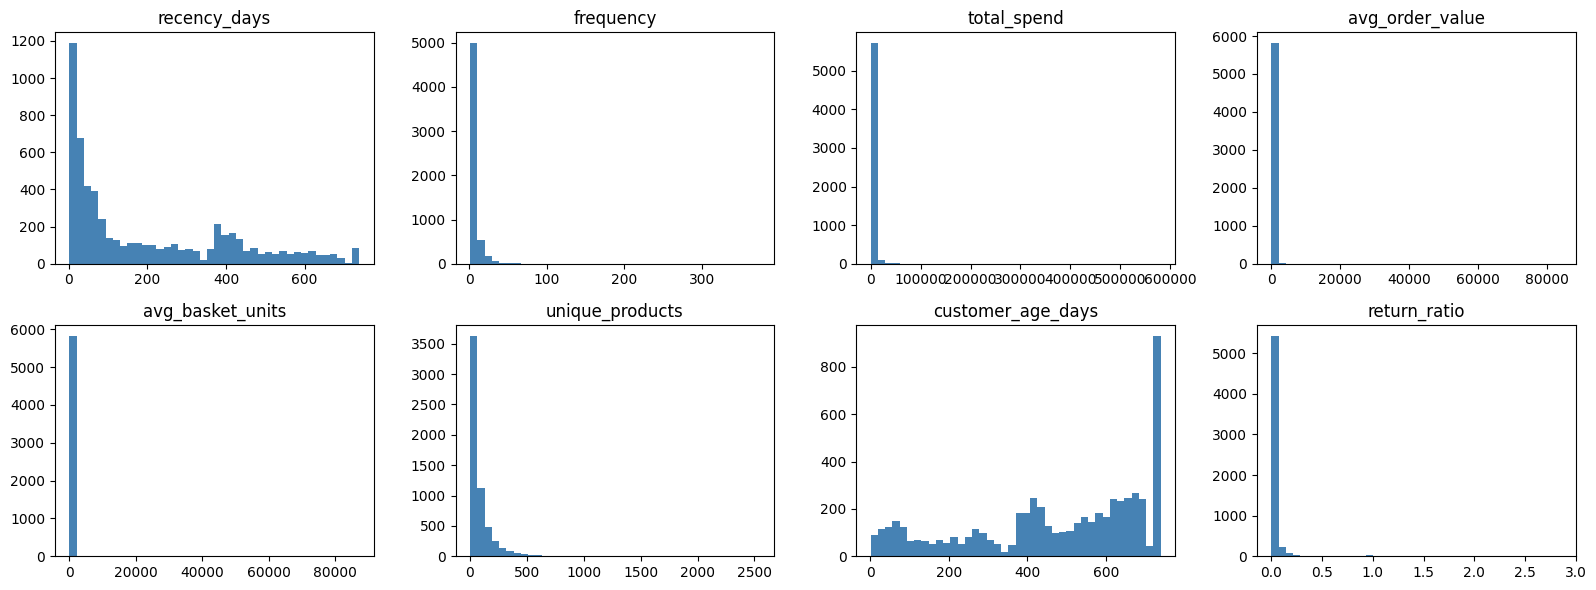

In [28]:
# Histograms of all eight features on the original scale
fig, axes = plt.subplots(2, 4, figsize=(16, 6))
for ax, col in zip(axes.ravel(), customers.columns):
    ax.hist(customers[col], bins=40, color='steelblue')
    ax.set_title(col)
plt.tight_layout()
plt.show()

### What I found

- Six of the eight features are very skewed to the right: `frequency` (12.08), `total_spend` (25.29), `avg_order_value` (57.61), `avg_basket_units` (47.43), `unique_products` (6.22) and `return_ratio` (11.79)
- In the histograms most customers are squeezed into the first bar, with a very long tail. For example `total_spend` has a mean of about 2,919 but a maximum of 580,987, which is roughly 20 times the 99th percentile (28,626)
- `recency_days` is moderately skewed (0.89), and `customer_age_days` is skewed the other way (-0.62), with a tall bar of customers whose first purchase was in the first days of the data

## Step 21: Comparing the Original Scale With log1p

**Why:** On the original scale, the distance between customers would be decided almost only by the few very big buyers, and everyone else would look close together. The log1p transform (log of 1 plus the value) shrinks the long tail, works on zeros, and makes a difference like "double the orders" count the same for small and large customers. I'm comparing the two treatments before I decide.

**What the code does:** Applies log1p to all features and compares skewness and the number of customers more than 3 standard deviations from the mean, before and after. Then draws the histograms again after the transform.

In [29]:
# log1p works on non-negative values and keeps zeros as zeros
customers_log = np.log1p(customers)

# customers more than 3 standard deviations from the mean
def beyond_3sd(df):
    z = (df - df.mean()) / df.std()
    return (z.abs() > 3).sum()

compare = pd.DataFrame({
    'skew_original': customers.skew(),
    'skew_log1p': customers_log.skew(),
    'beyond_3sd_original': beyond_3sd(customers),
    'beyond_3sd_log1p': beyond_3sd(customers_log)}).round(2)
compare

,skew_original,skew_log1p,beyond_3sd_original,beyond_3sd_log1p
recency_days,0.89,-0.49,0,0
frequency,12.08,1.00,62,49
total_spend,25.29,0.27,36,37
avg_order_value,57.61,0.05,18,71
avg_basket_units,47.43,-0.28,8,72
unique_products,6.22,-0.26,99,3
customer_age_days,-0.62,-2.05,0,123
return_ratio,11.79,7.70,75,95


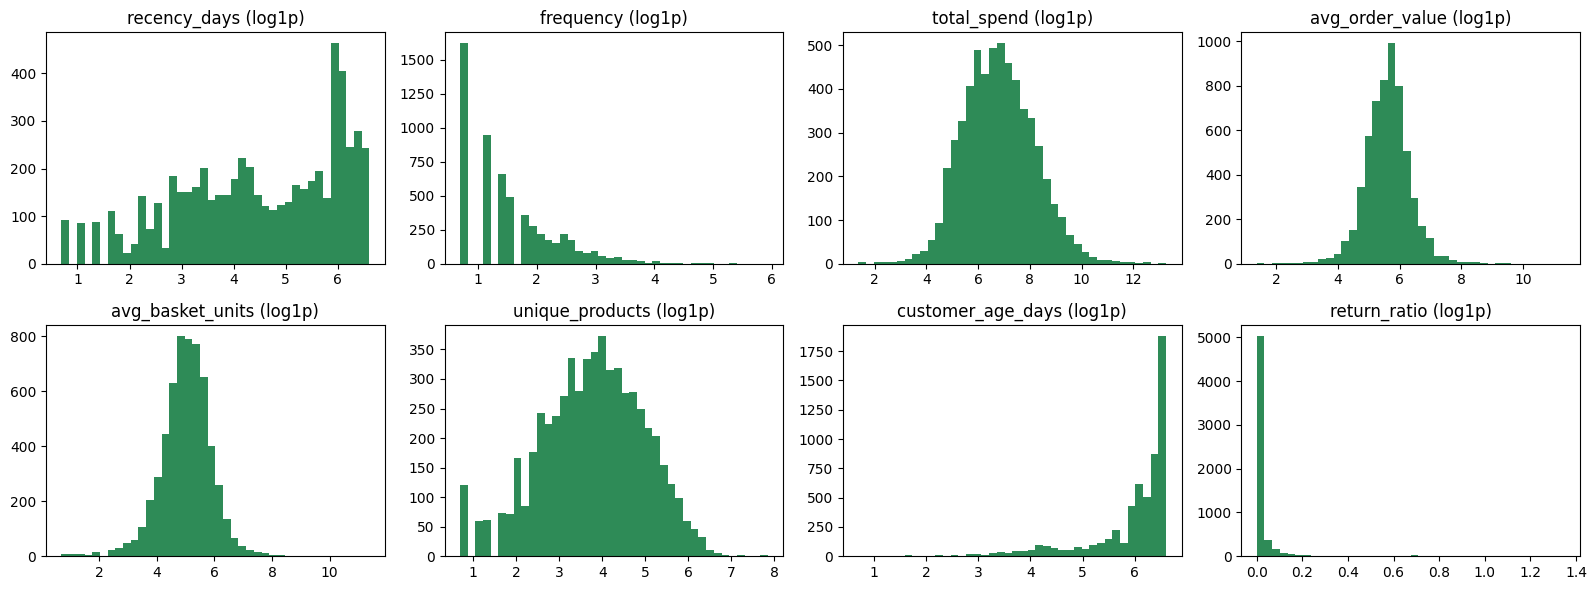

In [30]:
# Histograms of the same features after log1p
fig, axes = plt.subplots(2, 4, figsize=(16, 6))
for ax, col in zip(axes.ravel(), customers_log.columns):
    ax.hist(customers_log[col], bins=40, color='seagreen')
    ax.set_title(col + ' (log1p)')
plt.tight_layout()
plt.show()

### What I found

- log1p fixes most of the skew: `frequency` goes from 12.08 to 1.00, `total_spend` from 25.29 to 0.27, `avg_order_value` from 57.61 to 0.05, `avg_basket_units` from 47.43 to -0.28, `unique_products` from 6.22 to -0.26 and `recency_days` from 0.89 to -0.49
- It does not help two features. `customer_age_days` gets worse (-0.62 to -2.05), and `return_ratio` is still very skewed (7.70) because most customers have a return ratio of exactly 0
- The number of customers beyond 3 standard deviations drops for `frequency` (62 to 49) and `unique_products` (99 to 3), because the extreme high values are pulled in. It rises for `avg_order_value` (18 to 71) and `avg_basket_units` (8 to 72), because the log stretches the low end, so some very small orders are now far below the average
- So the transform changes what counts as "far apart", and it is not just a cosmetic fix
- My decision for now is to use log1p for the heavy-tailed features and leave `customer_age_days` on its original scale. I'll decide how to handle `return_ratio` when I build the final feature set

## Step 22: How Recency, Frequency and Spend Relate

**Why:** The first exploratory question is whether customers who bought recently also buy more often and spend more. This shows whether the features carry a real pattern, and how overlapping they are.

**What the code does:** Groups customers by how recently they bought and shows their size, median orders and median spend. Then prints how concentrated spending is and how many customers ordered only once, and draws frequency against total spend on log scales, coloured by recency.

In [31]:
# Customers grouped by how recently they bought
recency_group = pd.cut(customers['recency_days'], [0, 30, 90, 180, 365, 800],
                       labels=['0-30', '31-90', '91-180', '181-365', 'over 365'])
customers.groupby(recency_group, observed=True).agg(
    customers=('frequency', 'size'),
    median_orders=('frequency', 'median'),
    median_spend=('total_spend', 'median'))

,customers,median_orders,median_spend
recency_days,,,
0-30,1647,7.0,2055.090
31-90,1238,4.0,1200.490
91-180,587,4.0,981.180
181-365,794,2.0,603.535
over 365,1587,1.0,351.300


In [32]:
# Share of total spend from the top 1% and top 10% of customers
spend_sorted = customers['total_spend'].sort_values(ascending=False)
for pct in [0.01, 0.10]:
    top = spend_sorted.head(int(len(spend_sorted) * pct)).sum()
    print(f'Top {pct:.0%} of customers: {top / spend_sorted.sum():.1%} of total spend')

# customers who ordered only once
print('Customers with one order:', (customers['frequency'] == 1).sum(),
      f"({(customers['frequency'] == 1).mean():.1%})")

Top 1% of customers: 31.9% of total spend
Top 10% of customers: 63.9% of total spend
Customers with one order: 1619 (27.7%)


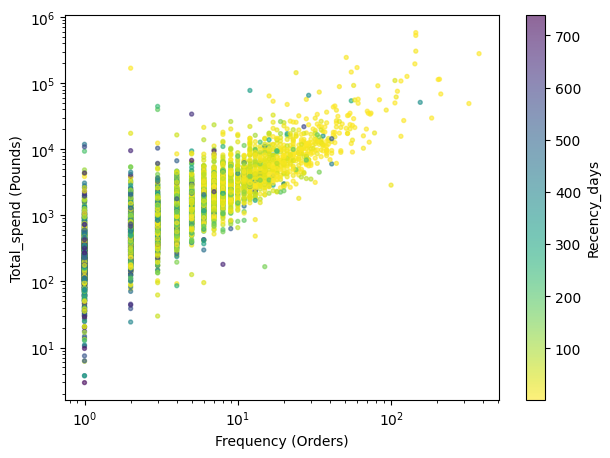

In [33]:
# Frequency against total spend on log scales, coloured by recency
plt.figure(figsize=(7, 5))
sc = plt.scatter(customers['frequency'], customers['total_spend'],
                 c=customers['recency_days'], cmap='viridis_r', s=8, alpha=0.6)
plt.xscale('log')
plt.yscale('log')
plt.colorbar(sc, label='Recency_days')
plt.xlabel('Frequency (Orders)')
plt.ylabel('Total_spend (Pounds)')
plt.show()

### What I found

- Customers who bought recently also buy more. The 1,647 customers who bought in the last 30 days have a median of 7 orders and a median spend of 2,055.09. The 1,587 customers who last bought over 365 days ago have a median of 1 order and 351.30
- **27.7% of customers (1,619) ordered only once**, and 27.1% (1,587) haven't bought in over a year
- Spending is very concentrated. The top 1% of customers account for **31.9%** of total spend and the top 10% for **63.9%**
- On the scatter plot, spend rises with the number of orders, and the recent buyers (yellow) sit in the upper right. Customers with one or two orders cover a huge range, from a few pounds to over ten thousand
- Frequency and total spend move together very closely, so I will check how much these features overlap when I look at correlations

## Step 23: Looking at Unusual Customers

**Why:** The brief asks me to find at least one unusual profile. A very high spend could mean a good customer, or it could be a data problem, so I want to look at both the biggest spenders and the customers with the highest return ratio.

**What the code does:** Shows the five customers with the highest total spend and the five with the highest return ratio, then counts how many customers have no returns, return more than half of what they bought, or return more than they bought.

In [34]:
# The five biggest spenders
customers.sort_values('total_spend', ascending=False).head(5)

,recency_days,frequency,total_spend,avg_order_value,avg_basket_units,unique_products,customer_age_days,return_ratio
Customer ID,,,,,,,,
18102,1,145,580987.04,4006.807172,1252.724138,382,739,0.004438
14646,2,145,526751.52,3632.769103,2531.531034,960,737,0.006737
14156,10,145,304719.88,2101.516414,1133.200000,1444,739,0.017376
14911,1,375,279477.79,745.274107,394.530667,2547,739,0.049308
17450,8,51,244784.25,4799.691176,1645.372549,144,438,0.045511


In [35]:
# The five customers with the highest return ratio
customers.sort_values('return_ratio', ascending=False).head(5)

,recency_days,frequency,total_spend,avg_order_value,avg_basket_units,unique_products,customer_age_days,return_ratio
Customer ID,,,,,,,,
15935,239,1,108.04,108.04,114.0,11,239,2.858386
13091,28,2,1108.80,554.40,669.0,40,730,2.211436
13112,541,1,20.60,20.60,11.0,2,541,1.264078
16446,1,2,168472.50,84236.25,40498.5,3,206,1.000036
12773,564,1,124.25,124.25,109.0,6,564,1.000000


In [36]:
print('Customers with no returns:', (customers['return_ratio'] == 0).sum(),
      f"({(customers['return_ratio'] == 0).mean():.1%})")
print('Returning more than half of what they bought:', (customers['return_ratio'] > 0.5).sum())
print('Returning more than they bought:', (customers['return_ratio'] > 1).sum())

Customers with no returns: 3429 (58.6%)
Returning more than half of what they bought: 39
Returning more than they bought: 4


### What I found

- The biggest spenders look genuine. Customer 18102 spent 580,987.04 across 145 orders and last bought 1 day before the snapshot, and all five have return ratios below 5%
- Customers **12346 and 16446 are atypical**. They look like big spenders (77,556.46 and 168,472.50), but they returned almost everything (return ratios of 0.995 and about 1.0). Customer 16446 has only 2 orders with an average order value of 84,236.25, the highest in the data
- Four customers have a return ratio above 1, so they returned more than they bought in this data. The highest is customer 15935 at 2.86, and I can't explain that from the data alone
- Returns are rare. **3,429 customers (58.6%)** have no returns and only 39 returned more than half of what they bought. So `return_ratio` is mostly zeros with a few extreme values, which will matter when I scale it
- These profiles show that `total_spend` alone can overstate a customer, so I'll keep `return_ratio` in the feature set. I'm leaving these customers in for now and will see how each algorithm treats them

## Step 24: Checking for Redundant Features

**Why:** If several features measure the same idea, that idea gets counted several times in the distance between customers and quietly gets more influence than the others. I want to find overlapping features before choosing the final set.

**What the code does:** Applies the log1p decision from Step 21, draws a correlation heatmap, lists pairs with a correlation above 0.7, checks whether `total_spend` is built from two other features, and shows the correlations left after dropping two features.

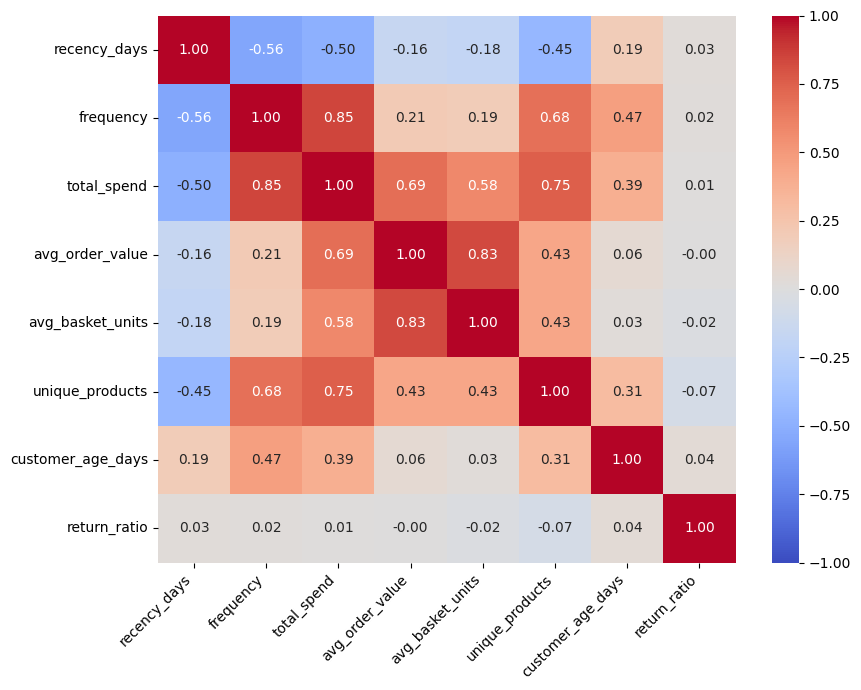

In [37]:
# applying the transform decided in step 21: log1p for every feature except customer_age_days
transformed = np.log1p(customers)
transformed['customer_age_days'] = customers['customer_age_days']

# correlations between features after the transform
corr = transformed.corr().round(2)
plt.figure(figsize=(9, 7))
sns.heatmap(corr, annot=True, cmap='coolwarm', vmin=-1, vmax=1, fmt='.2f')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

In [38]:
# pairs of features with a correlation above 0.7 (absolute value)
pairs = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack()
pairs[pairs.abs() > 0.7]

,,0
frequency,total_spend,0.85
total_spend,unique_products,0.75
avg_order_value,avg_basket_units,0.83


In [39]:
# total_spend is frequency times avg_order_value, so it adds no new information
np.allclose(customers['total_spend'], customers['frequency'] * customers['avg_order_value'])

True

In [40]:
# the features I keep, and their correlations after dropping the other two
features_kept = ['recency_days', 'frequency', 'avg_order_value', 'unique_products',
                 'customer_age_days', 'return_ratio']
transformed[features_kept].corr().round(2)

,recency_days,frequency,avg_order_value,unique_products,customer_age_days,return_ratio
recency_days,1.00,-0.56,-0.16,-0.45,0.19,0.03
frequency,-0.56,1.00,0.21,0.68,0.47,0.02
avg_order_value,-0.16,0.21,1.00,0.43,0.06,-0.00
unique_products,-0.45,0.68,0.43,1.00,0.31,-0.07
customer_age_days,0.19,0.47,0.06,0.31,1.00,0.04
return_ratio,0.03,0.02,-0.00,-0.07,0.04,1.00


### What I found

- Three pairs are highly correlated: `frequency` and `total_spend` (0.85), `avg_order_value` and `avg_basket_units` (0.83), and `total_spend` and `unique_products` (0.75)
- `total_spend` is exactly `frequency` times `avg_order_value`, so it adds nothing new. `avg_order_value` (pounds per order) and `avg_basket_units` (items per order) both describe how big a typical order is
- If I kept all eight features, four of them (`frequency`, `total_spend`, `avg_order_value`, `avg_basket_units`) would describe volume and money, so about half of the distance would depend on that one idea
- **I'm dropping `total_spend` and `avg_basket_units`** from the clustering input. I keep `avg_order_value` because it is almost independent of `frequency` (0.21). `total_spend` stays in the table so I can still report it in pounds when I describe the clusters
- With the six features left, the highest correlation is 0.68 (`frequency` and `unique_products`), then -0.56 (`recency_days` and `frequency`). I'm keeping both, because product variety and order count are related but are different ideas, and I'll mention the overlap as a limitation

## Step 25: Deciding How to Treat return_ratio

**Why:** `return_ratio` is zero for most customers and very large for a few, and in Step 21 log1p alone did not fix that. A few extreme values could dominate the distances, so I want to compare treatments before I choose one.

**What the code does:** Compares three versions of `return_ratio` (original, log1p, and capped at 1 before log1p) using skewness, the largest standardised value (max_z) and the number of customers beyond 3 standard deviations.

In [41]:
# three treatments of return_ratio
options = pd.DataFrame({
    'raw': customers['return_ratio'],
    'log1p': np.log1p(customers['return_ratio']),
    'capped_then_log1p': np.log1p(customers['return_ratio'].clip(upper=1))})
z = (options - options.mean()) / options.std()
pd.DataFrame({'skew': options.skew(), 'max_z': z.max(),
              'beyond_3sd': (z.abs() > 3).sum()}).round(2)

,skew,max_z,beyond_3sd
raw,11.79,29.35,75
log1p,7.70,19.36,95
capped_then_log1p,6.74,10.24,102


### What I found

- On the original scale `return_ratio` has a skew of 11.79 and its largest value is 29.35 standard deviations above the mean. With log1p these drop to 7.70 and 19.36, and with capping at 1 first they drop to 6.74 and 10.24
- Capping only changes the 4 customers whose ratio was above 1. I treat them as "returned everything", which is the most that can be returned
- The feature is still mostly zeros with a long tail, and 102 customers are more than 3 standard deviations from the mean. I accept that, because returns are a real behaviour I want to capture, and I plan to test the clustering without `return_ratio` as a sensitivity check later
- **Decision: cap at 1, then apply log1p**

## Step 26: Comparing Scaling Methods

**Why:** The features are in different units. The spread of `avg_order_value` is about 1,212 pounds, while `return_ratio` has a spread of about 0.10. Without scaling, the algorithms would measure distance almost only through the features with the biggest numbers. I'm comparing three scalers: StandardScaler (mean 0, spread 1), RobustScaler (median and interquartile range) and MinMaxScaler (squeezes into 0 to 1).

**What the code does:** Builds the final feature table (log1p on all features except `customer_age_days`, and `return_ratio` capped at 1 first), prints the original spread of each feature, applies the three scalers, and compares the smallest value, largest value and spread of each feature. It also draws boxplots for each scaler.

In [42]:
from sklearn.preprocessing import StandardScaler, RobustScaler, MinMaxScaler

# final features: log1p everywhere except customer_age_days, return_ratio capped at 1 first
final = transformed[features_kept].copy()
final['return_ratio'] = np.log1p(customers['return_ratio'].clip(upper=1))

# spread of each feature on its original scale, before any transform or scaling
customers[features_kept].std().round(2)

,0
recency_days,208.53
frequency,12.76
avg_order_value,1212.45
unique_products,116.50
customer_age_days,223.20
return_ratio,0.10


In [43]:
scalers = {'standard': StandardScaler(), 'robust': RobustScaler(), 'minmax': MinMaxScaler()}
scaled = {name: pd.DataFrame(s.fit_transform(final), columns=final.columns, index=final.index)
          for name, s in scalers.items()}

# smallest value, largest value and spread of each feature under each scaler
pd.concat({name: df.agg(['min', 'max', 'std']).T for name, df in scaled.items()}, axis=1).round(2)

standard             robust              minmax           
                       min    max  std    min    max   std    min  max   std
recency_days         -2.41   1.38  1.0  -1.44   0.76  0.58    0.0  1.0  0.26
frequency            -1.06   5.42  1.0  -0.50   3.28  0.58    0.0  1.0  0.15
avg_order_value      -5.80   7.84  1.0  -5.05   6.77  0.87    0.0  1.0  0.07
unique_products      -2.55   3.37  1.0  -1.90   2.43  0.73    0.0  1.0  0.17
customer_age_days    -2.12   1.19  1.0  -1.49   0.59  0.63    0.0  1.0  0.30
return_ratio         -0.32  10.24  1.0   0.00  47.40  4.49    0.0  1.0  0.09

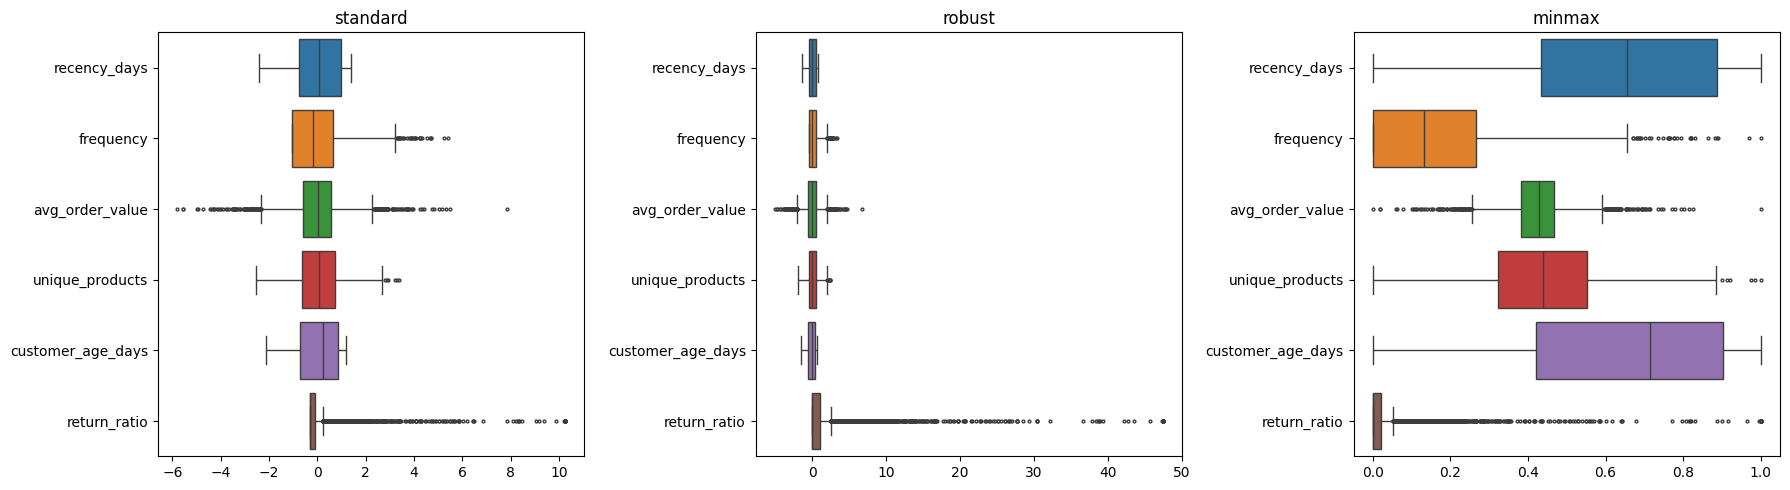

In [44]:
# boxplots of the features under each scaler
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, (name, df) in zip(axes, scaled.items()):
    sns.boxplot(data=df, orient='h', ax=ax, fliersize=2)
    ax.set_title(name)
plt.tight_layout()
plt.show()

### What I found

- On the original scale the spreads are very different: `avg_order_value` 1,212.45 pounds, `recency_days` 208.53 days, `customer_age_days` 223.20 days, `unique_products` 116.50, `frequency` 12.76 and `return_ratio` 0.10. Without scaling, `avg_order_value` would dominate the distances and `return_ratio` would hardly matter
- **StandardScaler** gives every feature a spread of exactly 1, so each starts with equal weight. The long tails stay visible (for example `return_ratio` goes up to 10.24)
- **RobustScaler** divides by the interquartile range. Most customers have a `return_ratio` of 0, so that range is tiny and the scaled values go up to 47.40, with a spread of 4.49 compared with 0.58 to 0.87 for the others. That one feature would dominate the distances
- **MinMaxScaler** puts everything between 0 and 1, but the outliers squash most customers into a small part of the range. The spread is only 0.07 for `avg_order_value` and 0.09 for `return_ratio`, against 0.26 for `recency_days` and 0.30 for `customer_age_days`. So the last two would count about three to four times more
- **Decision: StandardScaler for the main experiment.** I'll test RobustScaler later as a sensitivity check

## Step 27: Building the Final Feature Matrix

**Why:** The brief says K-Means, Hierarchical Clustering and DBSCAN must be compared on the same prepared features, so I'm building one final matrix called X and will use it for all three.

**What the code does:** Takes the standard-scaled features as X, prints its shape, and checks that every feature has a mean of 0 and a spread of 1.

In [45]:
# the final matrix used for all three algorithms
X = scaled['standard']
print(X.shape)
X.describe().round(2)

(5853, 6)


,recency_days,frequency,avg_order_value,unique_products,customer_age_days,return_ratio
count,5853.00,5853.00,5853.00,5853.00,5853.00,5853.00
mean,0.00,-0.00,-0.00,0.00,-0.00,0.00
std,1.00,1.00,1.00,1.00,1.00,1.00
min,-2.41,-1.06,-5.80,-2.55,-2.12,-0.32
25%,-0.76,-1.06,-0.60,-0.64,-0.73,-0.32
50%,0.07,-0.20,0.03,0.05,0.25,-0.32
75%,0.96,0.66,0.56,0.72,0.86,-0.09
max,1.38,5.42,7.84,3.37,1.19,10.24


### What I found

- X has **5,853 rows (customers) and 6 features**: `recency_days`, `frequency`, `avg_order_value`, `unique_products`, `customer_age_days` and `return_ratio`
- Every feature has a mean of 0 and a spread of 1, as expected
- 27.7% of customers have only 1 order, so the lowest quarter of `frequency` is a single value (-1.06). The lowest three quarters of `return_ratio` are about -0.32 because most customers have no returns. Distance-based methods will see these as big groups of identical customers

## Step 28: Preprocessing Log

The data went from 1,067,371 rows to 794,454 rows after cleaning (74.4% kept), and ended as one table of 5,853 customers.

| Step | Action | Affected | Why |
|---|---|---|---|
| 8 | Removed rows with no Customer ID | 243,007 rows | They can't be linked to a customer |
| 10 | Removed exact duplicate rows | 26,479 rows | They would count a purchase twice |
| 11 | Removed non-product stock codes | 3,368 rows | Fees, postage and adjustments are not purchases |
| 12 | Removed zero-price rows | 63 rows | No spending to measure |
| 13 | Split cancellations from sales | 17,597 return rows, 776,857 sales rows | A cancellation is not a purchase |
| 13 | Left out customers with only returns | 23 customers | No buying behaviour to measure |
| 15 | Built one row per customer | 5,853 customers, 8 features | The analysis unit is a customer |
| 21 | Applied log1p to the heavy-tailed features | All features except `customer_age_days` | Reduces the long tails |
| 24 | Dropped `total_spend` and `avg_basket_units` | 2 features | Redundant with other features |
| 25 | Capped `return_ratio` at 1 before log1p | 4 customers | Limits the influence of extreme ratios |
| 26 | Standard scaling | All 6 features | Gives each feature equal starting weight |

# Task C: Clustering Model Development

## Step 29: Recording Versions and Starting K-Means

**Why:** The assignment asks for the software versions and the random seed, so anyone can repeat my results. K-Means is also the first algorithm, so I import everything I need for it here.

**What the code does:** Imports K-Means and the scoring functions, then prints the library versions and the seed.

In [46]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score, adjusted_rand_score
import sklearn

# versions and seed are printed because the assignment asks for them
print('scikit-learn', sklearn.__version__, '| numpy', np.__version__, '| pandas', pd.__version__)
print('random seed:', RANDOM_SEED)

scikit-learn 1.6.1 | numpy 2.4.6 | pandas 2.2.3
random seed: 42


## Step 30: Running K-Means for k = 2 to 8

**Why:** K-Means needs me to choose the number of clusters in advance, so I try every k from 2 to 8 and compare them with several scores instead of guessing. I use k-means++ so the starting points are spread out, and 10 starts per k so one bad start doesn't decide the result.

**What the code does:** Fits K-Means for each k on the scaled matrix X and saves the labels. It then builds a table with inertia (how tight the clusters are), silhouette (higher is better), Davies-Bouldin (lower is better), Calinski-Harabasz (higher is better) and the size of the smallest cluster.

In [47]:
# k-means++ start, 10 starts for each k, same seed every time
results = []
kmeans_labels = {}
for k in range(2, 9):
    km = KMeans(n_clusters=k, init='k-means++', n_init=10, random_state=RANDOM_SEED).fit(X)
    kmeans_labels[k] = km.labels_
    results.append({'k': k,
                    'inertia': km.inertia_,
                    'silhouette': silhouette_score(X, km.labels_),
                    'davies_bouldin': davies_bouldin_score(X, km.labels_),
                    'calinski_harabasz': calinski_harabasz_score(X, km.labels_),
                    'smallest_cluster': np.bincount(km.labels_).min()})
kmeans_results = pd.DataFrame(results).set_index('k').round(3)
kmeans_results

,inertia,silhouette,davies_bouldin,calinski_harabasz,smallest_cluster
k,,,,,
2,25610.465,0.268,1.413,2172.104,2417
3,21371.464,0.264,1.363,1881.421,1456
4,17574.459,0.278,1.136,1946.237,79
5,15377.077,0.238,1.188,1876.900,78
6,14124.711,0.208,1.271,1738.073,78
7,13180.944,0.201,1.308,1621.588,78
8,12364.229,0.204,1.259,1536.655,37


### What I found

- **k = 4 has the best silhouette (0.278) and the best Davies-Bouldin (1.136)**
- Calinski-Harabasz is highest at k = 2 (2,172) and second highest at k = 4 (1,946), so that score doesn't contradict k = 4 strongly
- All silhouette scores are low, between 0.20 and 0.28, so the groups overlap and are not sharply separated. This is normal for customer behaviour, but I shouldn't describe them as clear-cut
- From k = 4 onwards the smallest cluster is tiny (79, 78, 78, 78 and 37 customers), so I need to look at what that small cluster is

## Step 31: Elbow Plot and Validation Scores

**Why:** A picture makes it easier to see where adding more clusters stops helping, and whether the scores agree with each other.

**What the code does:** Plots inertia, silhouette, Davies-Bouldin and Calinski-Harabasz against k, then prints how much inertia drops with each extra cluster.

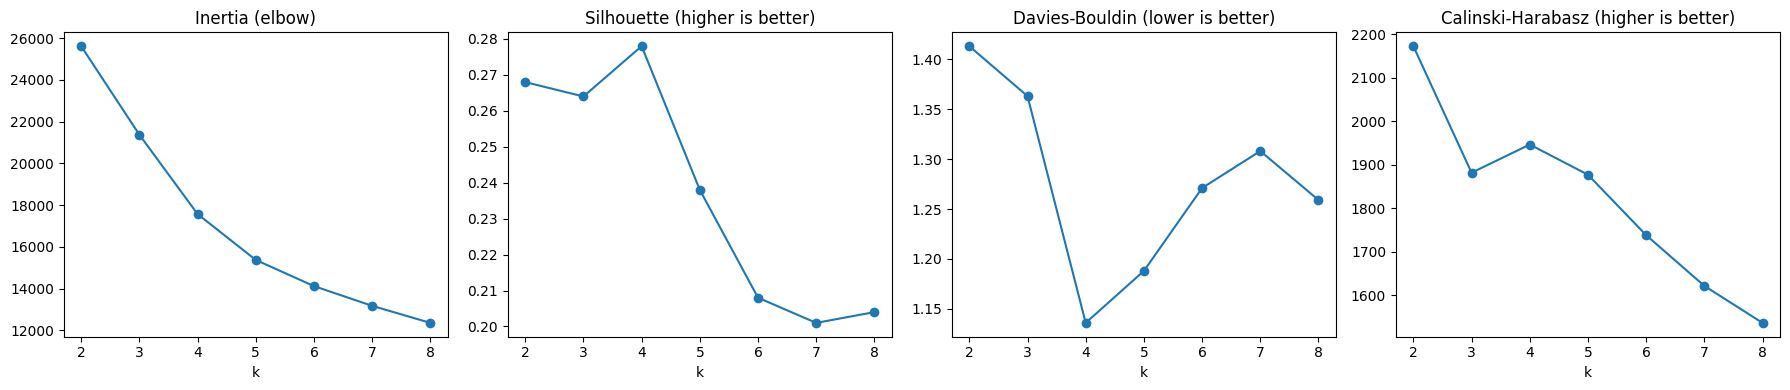

In [48]:
# elbow plot and the three validation scores for each k
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
titles = {'inertia': 'Inertia (elbow)',
          'silhouette': 'Silhouette (higher is better)',
          'davies_bouldin': 'Davies-Bouldin (lower is better)',
          'calinski_harabasz': 'Calinski-Harabasz (higher is better)'}
for ax, (col, title) in zip(axes, titles.items()):
    ax.plot(kmeans_results.index, kmeans_results[col], marker='o')
    ax.set_title(title)
    ax.set_xlabel('k')
plt.tight_layout()
plt.show()

In [49]:
# how much the inertia falls when one more cluster is added
kmeans_results['inertia'].diff().mul(-1).round(0)

,inertia
k,
2,NaN
3,4239.0
4,3797.0
5,2197.0
6,1252.0
7,944.0
8,817.0


### What I found

- Inertia falls steadily with no sharp elbow. The drops are 4,239 (k=3), 3,797 (k=4), 2,197 (k=5), 1,252 (k=6), 944 (k=7) and 817 (k=8)
- The biggest change in the drop is after k = 4, where the saving falls from 3,797 to 2,197, so the elbow is around k = 4 but it is soft
- Silhouette peaks at k = 4 and falls sharply after k = 5
- Davies-Bouldin has a clear minimum at k = 4 and gets worse for larger k

## Step 32: Cluster Sizes and a First Look at k = 4

**Why:** A good score doesn't help if the clusters are too small to act on. I want to see the size of every cluster, and what the k = 4 clusters actually contain, before I commit to a k.

**What the code does:** Prints the cluster sizes for every k, then shows the median of each feature (in original units, not scaled) for each k = 4 cluster. It also checks which cluster customers 12346, 16446 and 18102 fall into. The first two are the unusual customers from Step 23, and 18102 is the biggest spender.

In [50]:
# size of each cluster for every k, largest first
for k in range(2, 9):
    print(k, sorted(np.bincount(kmeans_labels[k]).tolist(), reverse=True))

2 [3436, 2417]
3 [2418, 1979, 1456]
4 [2400, 1941, 1433, 79]
5 [1766, 1508, 1286, 1215, 78]
6 [1421, 1284, 1200, 970, 900, 78]
7 [1318, 1190, 888, 855, 792, 732, 78]
8 [1296, 1149, 870, 845, 793, 708, 155, 37]


In [51]:
# median of each feature (original units) for the k = 4 clusters, a first look before the full profiling
customers_k4 = customers.assign(cluster=kmeans_labels[4])
customers_k4.groupby('cluster').agg(
    customers=('frequency', 'size'),
    recency_days=('recency_days', 'median'),
    frequency=('frequency', 'median'),
    avg_order_value=('avg_order_value', 'median'),
    unique_products=('unique_products', 'median'),
    customer_age_days=('customer_age_days', 'median'),
    return_ratio=('return_ratio', 'median'),
    total_spend=('total_spend', 'median')).round(2)

,customers,recency_days,frequency,avg_order_value,unique_products,customer_age_days,return_ratio,total_spend
cluster,,,,,,,,
0,1941,29.0,9.0,340.69,132.0,662.0,0.01,3245.43
1,1433,38.0,2.0,283.67,33.0,129.0,0.00,592.51
2,2400,396.0,2.0,221.29,24.0,554.0,0.00,406.58
3,79,277.0,2.0,190.48,11.0,456.0,0.50,385.19


In [52]:
# which cluster the unusual customers from step 23 and the biggest spender fall into
customers_k4.loc[[12346, 16446, 18102], 'cluster']

,cluster
Customer ID,
12346,3
16446,3
18102,0


### What I found

- At k = 4 the sizes are **2,400, 1,941, 1,433 and 79**. At k = 5, 6 and 7 the same small cluster stays at 78 customers, so it is a real group and not a one-off
- **Cluster 0 (1,941):** bought recently (median 29 days ago), orders often (9), has the most products (132) and has been a customer the longest (662 days). Median spend is 3,245. These look like my loyal regulars
- **Cluster 1 (1,433):** also bought recently (38 days) but only 2 orders and a customer age of just 129 days. These look like new customers
- **Cluster 2 (2,400):** last bought a median of 396 days ago with 2 orders and low spend (407). These look like lapsed or low-activity customers
- **Cluster 3 (79):** median return ratio of 0.50, so they return about half of what they spend. Their recency is 277 days, with 2 orders and only 11 products. This is a small group of heavy returners
- 12346 and 16446 are both in cluster 3, so the unusual customers I worried about in Step 23 end up grouped together instead of distorting another cluster. 18102 is in cluster 0

## Step 33: Checking Stability Across Random Seeds

**Why:** K-Means starts from random points, so a different seed can give different clusters. If the groups change a lot between seeds, I can't trust them. The assignment asks for at least three seeds, so I use five.

**What the code does:** Refits k = 4 with five seeds. It then compares every pair of runs with the adjusted Rand index (ARI), where 1 means the two runs grouped customers identically. Finally it prints inertia and cluster sizes for each seed.

In [53]:
# refitting k = 4 with five different random seeds
seeds = [42, 7, 123, 2024, 99]
seed_fits = {s: KMeans(n_clusters=4, init='k-means++', n_init=10, random_state=s).fit(X) for s in seeds}

# adjusted rand index between every pair of runs (1 means identical groups)
ari = pd.DataFrame([[adjusted_rand_score(seed_fits[a].labels_, seed_fits[b].labels_) for b in seeds]
                    for a in seeds], index=seeds, columns=seeds).round(3)
ari

,42,7,123,2024,99
42,1.000,1.000,0.992,0.999,0.986
7,1.000,1.000,0.992,0.999,0.986
123,0.992,0.992,1.000,0.993,0.978
2024,0.999,0.999,0.993,1.000,0.984
99,0.986,0.986,0.978,0.984,1.000


In [54]:
for s, km in seed_fits.items():
    print('seed', s, '| inertia', round(km.inertia_, 1), '| sizes', sorted(np.bincount(km.labels_).tolist(), reverse=True))

seed 42 | inertia 17574.5 | sizes [2400, 1941, 1433, 79]
seed 7 | inertia 17574.5 | sizes [2400, 1941, 1433, 79]
seed 123 | inertia 17574.7 | sizes [2402, 1945, 1427, 79]
seed 2024 | inertia 17574.5 | sizes [2403, 1941, 1430, 79]
seed 99 | inertia 17574.8 | sizes [2386, 1945, 1443, 79]


### What I found

- Every pair of seeds has an **ARI of 0.978 or higher**, so the clusters are very stable
- Inertia is almost the same for all seeds (17,574.5 to 17,574.8)
- The small cluster is exactly 79 customers in every run
- The only differences are a handful of customers near the edges between the three big clusters (for example 2,386 to 2,403 in the largest cluster)

## Step 34: Choosing k for K-Means

**Why:** The assignment asks me to justify k with more than one piece of evidence, and to be clear about what K-Means assumes, because that affects how far I can trust it.

**What K-Means assumes:** It measures straight-line (Euclidean) distance to a cluster centre, so it works best when clusters are roughly round and similar in size. It is sensitive to feature scale and to outliers, which is why I log-transformed and standardised first. It always forces every customer into a cluster, so it has no way to say "this customer doesn't belong anywhere".

### What I found

- **I choose k = 4.** It has the best silhouette and Davies-Bouldin, a soft elbow, the second best Calinski-Harabasz and a seed stability ARI of 0.978 or more
- The weakness is cluster 3 with only 79 customers (1.3%). It is driven by return ratio, since its centre on the scaled return ratio is about 7 standard deviations above average, so it is a niche rather than a main segment. It is still useful because heavy returners need different handling from everyone else
- **k = 3 is my fallback.** It has no tiny cluster (smallest is 1,456) and almost the same silhouette (0.264), but a worse Davies-Bouldin (1.363) and it hides the returners group
- I will keep k = 3 and k = 4 for the comparison with the other algorithms and the sensitivity checks in Task D

## Step 35: Hierarchical Clustering (Ward, Average and Complete Linkage)

**Why:** Hierarchical clustering doesn't need k in advance. It builds a tree by merging the closest customers step by step, and I can cut the tree at different heights. The linkage rule decides what "closest" means between groups, so I compare three: Ward (merges that add the least spread), average and complete.

**What the code does:** Builds the full tree for all 5,853 customers with each linkage (this is small enough that I don't need to sample). It then prints the cophenetic correlation, which shows how well the tree keeps the original distances between customers (closer to 1 is better).

In [55]:
from scipy.cluster.hierarchy import linkage, fcluster, dendrogram, cophenet
from scipy.spatial.distance import pdist

# 5,853 customers is small enough to run hierarchical clustering on everyone
dist = pdist(X)
links = {m: linkage(X, method=m) for m in ['ward', 'average', 'complete']}
for m, Z in links.items():
    print(m, '| cophenetic correlation:', round(cophenet(Z, dist)[0], 3))

ward | cophenetic correlation: 0.402
average | cophenetic correlation: 0.739
complete | cophenetic correlation: 0.523


### What I found

- Cophenetic correlation is 0.402 for Ward, 0.523 for complete and 0.739 for average
- Average linkage keeps the distances best, but a high value here doesn't mean it gives useful groups. I'll check that in the next steps

## Step 36: Dendrograms

**Why:** The assignment asks for a dendrogram, and the tree shows where natural cut points are. A tree of 5,853 leaves can't be read, so I draw it for a random sample of 400 customers (same seed each time) and show only the last 30 merges.

**What the code does:** Draws one dendrogram per linkage for the same sample.

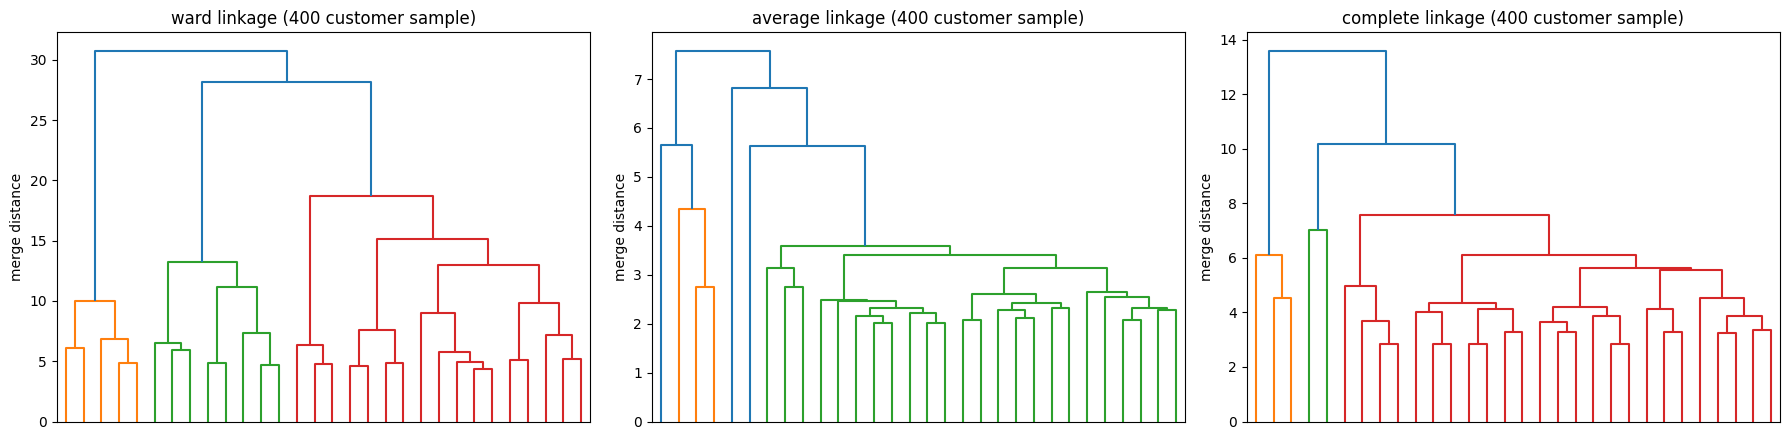

In [56]:
# dendrogram on a random sample of 400 customers, the full tree would be unreadable
rng = np.random.RandomState(RANDOM_SEED)
sample_idx = rng.choice(len(X), 400, replace=False)
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
for ax, m in zip(axes, ['ward', 'average', 'complete']):
    dendrogram(linkage(X.iloc[sample_idx], method=m), no_labels=True, truncate_mode='lastp', p=30, ax=ax)
    ax.set_title(m + ' linkage (400 customer sample)')
    ax.set_ylabel('merge distance')
plt.tight_layout()
plt.show()

### What I found

- **Ward** has a balanced tree. There are a few large merges at the top and a clear jump in height before the last two or three merges, which suggests about 3 or 4 groups
- **Average** and **complete** look different. One or two tiny branches join the rest only at the very top, and the bulk of the customers merge into one big block at low heights. Cutting these trees gives one huge cluster plus a few odd customers
- This is the typical "chaining" problem of average linkage on data with outliers, and it is a first sign that Ward will be the more useful one for segmentation

## Step 37: Cutting the Trees at 3, 4 and 5 Clusters

**Why:** The assignment asks for at least three cut levels and more than one internal metric. I cut each tree at k = 3, 4 and 5, score every result on all customers, and look at the cluster sizes, because a high score on a useless split (one giant cluster) is not a good result.

**What the code does:** Cuts each tree, then builds a table with silhouette, Davies-Bouldin, Calinski-Harabasz, the smallest cluster size and all cluster sizes.

In [57]:
# cutting each tree into 3, 4 and 5 clusters and scoring them on all customers
hier_labels = {}
rows = []
for m, Z in links.items():
    for k in [3, 4, 5]:
        lab = fcluster(Z, k, criterion='maxclust') - 1
        hier_labels[(m, k)] = lab
        sizes = sorted(np.bincount(lab).tolist(), reverse=True)
        rows.append({'linkage': m, 'k': k,
                     'silhouette': silhouette_score(X, lab),
                     'davies_bouldin': davies_bouldin_score(X, lab),
                     'calinski_harabasz': calinski_harabasz_score(X, lab),
                     'smallest': sizes[-1], 'sizes': sizes})
hier_results = pd.DataFrame(rows).set_index(['linkage', 'k'])
hier_results[['silhouette', 'davies_bouldin', 'calinski_harabasz']] = hier_results[['silhouette', 'davies_bouldin', 'calinski_harabasz']].round(3)
hier_results

silhouette  davies_bouldin  calinski_harabasz  smallest  \
linkage  k                                                            
ward     3       0.226           1.504           1611.571      1547   
         4       0.241           1.237           1656.496        64   
         5       0.205           1.245           1498.067        64   
average  3       0.613           0.962            391.424         6   
         4       0.612           0.840            262.876         1   
         5       0.523           0.761            217.703         1   
complete 3       0.535           1.056            383.901         7   
         4       0.185           1.466            805.187         7   
         5       0.180           1.695            928.537         7   

                                  sizes  
linkage  k                               
ward     3           [2493, 1813, 1547]  
         4       [2429, 1813, 1547, 64]  
         5  [1955, 1813, 1547, 474, 64]  
average  3                [5777, 70, 6]  
         4             [5777, 70, 5, 1]  
         5         [5777, 47, 23, 5, 1]  
complete 3               [5737, 109, 7]  
         4         [2902, 2835, 109, 7]  
         5    [2902, 1960, 875, 109, 7]

### What I found

- **Average linkage has the best-looking scores** (silhouette 0.61, Davies-Bouldin 0.84 to 0.96), but they are misleading. At k = 3 it gives clusters of 5,777, 70 and 6 customers, so 98.7% of customers are in one cluster. The score is high only because the tiny clusters are far away from everyone else
- **Complete linkage at k = 3** has the same problem (5,737, 109 and 7). At k = 4 it splits the big cluster in two (2,902 and 2,835) but the silhouette drops to 0.185 and the 7-customer cluster stays
- **Ward is the only linkage that gives usable groups.** At k = 4 the sizes are 2,429, 1,813, 1,547 and 64, with silhouette 0.241, Davies-Bouldin 1.237 and Calinski-Harabasz 1,656. Its Calinski-Harabasz is also far higher than average or complete (1,656 against 263 and 805 at k = 4)
- Within Ward, k = 4 beats k = 3 and k = 5 on all three scores
- Ward's scores are a bit lower than K-Means at the same k (silhouette 0.241 against 0.278 at k = 4), which is expected because K-Means directly optimises the compactness that these scores reward

## Step 38: How Close Ward Is to K-Means, and What Its Clusters Look Like

**Why:** If Ward and K-Means find similar groups, that is extra evidence the groups are real. If they disagree a lot, I should be careful. I also want to check that the Ward clusters mean the same thing as the K-Means ones.

**What the code does:** Compares Ward with K-Means at the same k using the adjusted Rand index, then shows the median features of each Ward k = 4 cluster in original units.

In [58]:
# how close ward is to k-means at the same k (ari of 1 means identical groups)
for k in [3, 4, 5]:
    km_lab = KMeans(n_clusters=k, init='k-means++', n_init=10, random_state=RANDOM_SEED).fit(X).labels_
    print('k =', k, '| ward vs k-means ARI:', round(adjusted_rand_score(km_lab, hier_labels[('ward', k)]), 3))

k = 3 | ward vs k-means ARI: 0.673
k = 4 | ward vs k-means ARI: 0.685
k = 5 | ward vs k-means ARI: 0.489


In [59]:
# median features of the ward k = 4 clusters, original units
customers.assign(cluster=hier_labels[('ward', 4)]).groupby('cluster').agg(
    customers=('frequency', 'size'),
    recency_days=('recency_days', 'median'),
    frequency=('frequency', 'median'),
    avg_order_value=('avg_order_value', 'median'),
    unique_products=('unique_products', 'median'),
    customer_age_days=('customer_age_days', 'median'),
    return_ratio=('return_ratio', 'median')).round(2)

,customers,recency_days,frequency,avg_order_value,unique_products,customer_age_days,return_ratio
cluster,,,,,,,
0,1813,29.0,9.0,345.27,131.0,658.0,0.01
1,1547,39.0,2.0,245.16,30.0,146.0,0.00
2,64,289.0,1.5,167.66,9.5,427.0,0.72
3,2429,397.0,2.0,242.07,26.0,563.0,0.00


### What I found

- Ward and K-Means agree fairly well at k = 4 (ARI **0.685**) and k = 3 (0.673), and less at k = 5 (0.489). So k = 4 is the level where the two methods agree most, which supports choosing it
- The Ward k = 4 clusters have the same story as K-Means: 1,813 recent, frequent, long-standing customers (29 days, 9 orders, 131 products), 1,547 new customers (customer age 146 days), 2,429 lapsed customers (397 days since last order) and a small group of 64 heavy returners (median return ratio 0.72)
- The differences are at the edges: Ward's returners group is smaller (64 against 79) and its lapsed group is bigger (2,429 against 2,400)
- My conclusion is that hierarchical clustering finds the same four customer types as K-Means, but only with Ward linkage. Average and complete linkage are not suitable here because outliers make them produce one giant cluster

## Step 39: DBSCAN and the k-distance Plot

**Why:** DBSCAN finds dense areas and treats everything else as noise, so it doesn't need k and can spot outliers. It needs two settings: `eps` (how close two customers must be to count as neighbours) and `min_samples` (how many neighbours make a dense area). I pick eps from a k-distance plot, which shows how far each customer is from its 12th nearest neighbour (12 is twice the number of features, a common starting rule). A good eps is near the bend where the curve starts rising steeply.

**What the code does:** Calculates that distance for every customer, sorts it, plots it and prints a summary of the values.

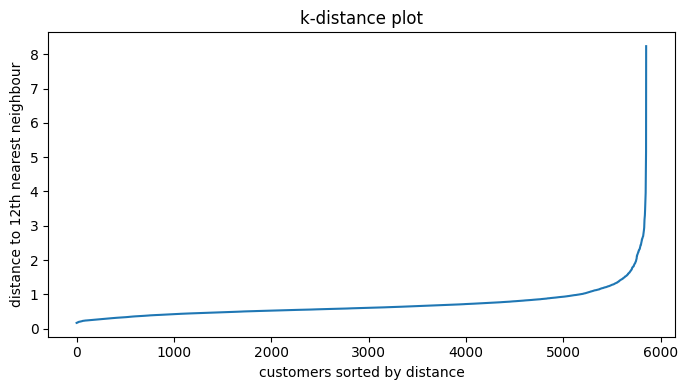

count    5853.00
mean        0.69
std         0.41
min         0.17
50%         0.60
75%         0.78
90%         1.07
95%         1.36
99%         2.43
max         8.23
dtype: float64


In [60]:
from sklearn.cluster import DBSCAN
from sklearn.neighbors import NearestNeighbors

# distance from each customer to its 12th nearest neighbour (12 = 2 x number of features)
nn = NearestNeighbors(n_neighbors=12).fit(X)
kdist = np.sort(nn.kneighbors(X)[0][:, -1])

plt.figure(figsize=(7, 4))
plt.plot(kdist)
plt.xlabel('customers sorted by distance')
plt.ylabel('distance to 12th nearest neighbour')
plt.title('k-distance plot')
plt.tight_layout()
plt.show()
print(pd.Series(kdist).describe(percentiles=[.5, .75, .9, .95, .99]).round(2))

### What I found

- The curve is flat for most customers (median distance 0.60, 75th percentile 0.78) and then bends upward near the 90th to 95th percentile (1.07 to 1.36)
- It shoots up for the last 1% of customers (above 2.43, maximum 8.23). These are the isolated customers
- So the sensible range for eps is roughly **0.8 to 1.5**. The bend is not sharp, which already suggests there is no clean separation between dense groups and the rest

## Step 40: Trying Different eps and min_samples

**Why:** DBSCAN results change a lot with its two settings, so I test a grid of 12 combinations (min_samples 6, 12, 24 and eps 0.5, 0.8, 1.1, 1.5) instead of trusting one. The grid goes a bit below my eps range so I can see what happens when eps is too small.

**What the code does:** Runs DBSCAN for each combination and counts the clusters, core points (clearly inside a dense area), border points (near a dense area but not inside it) and noise points. It also records the largest cluster size and the silhouette, calculated only on non-noise customers and only when there are 2 or more clusters.

In [61]:
# trying a grid of eps and min_samples values
rows = []
dbscan_labels = {}
for min_s in [6, 12, 24]:
    for eps in [0.5, 0.8, 1.1, 1.5]:
        lab = DBSCAN(eps=eps, min_samples=min_s).fit(X)
        l = lab.labels_
        dbscan_labels[(eps, min_s)] = l
        n_clusters = len(set(l)) - (1 if -1 in l else 0)
        core = len(lab.core_sample_indices_)
        noise = (l == -1).sum()
        mask = l != -1
        sil = silhouette_score(X[mask], l[mask]) if n_clusters > 1 else np.nan
        rows.append({'eps': eps, 'min_samples': min_s, 'clusters': n_clusters,
                     'core': core, 'border': len(l) - core - noise, 'noise': noise,
                     'noise_%': round(100 * noise / len(l), 1),
                     'largest_cluster': np.bincount(l[mask]).max() if mask.any() else 0,
                     'silhouette_non_noise': round(sil, 3)})
dbscan_grid = pd.DataFrame(rows)
dbscan_grid

,eps,min_samples,clusters,core,border,noise,noise_%,largest_cluster,silhouette_non_noise
0,0.5,6,21,2883,855,2115,36.1,2292,-0.250
1,0.8,6,2,5000,328,525,9.0,5327,-0.106
2,1.1,6,1,5517,132,204,3.5,5649,NaN
3,1.5,6,2,5711,75,67,1.1,5776,0.719
4,0.5,12,5,1697,978,3178,54.3,1241,-0.019
5,0.8,12,1,4502,648,703,12.0,5150,NaN
6,1.1,12,1,5307,274,272,4.6,5581,NaN
7,1.5,12,1,5631,116,106,1.8,5747,NaN
8,0.5,24,3,828,718,4307,73.6,1051,0.173
9,0.8,24,1,3751,1182,920,15.7,4933,NaN


### What I found

- **Small eps (0.5) breaks the data apart.** With min_samples 6 it gives 21 clusters and marks 36% of customers as noise. With min_samples 24 it marks 74% as noise
- **From eps 0.8 upwards, DBSCAN finds one giant cluster.** For example, eps 1.1 with min_samples 12 gives 1 cluster of 5,581 customers (95%) and 272 noise points (4.6%)
- The only settings that give two clusters are min_samples 6 with eps 0.8 or 1.5, and the second cluster is tiny. Its silhouette of 0.719 at eps 1.5 only looks good because it compares one huge blob with a handful of points
- No setting separates the customers into several balanced groups. The data is one continuous cloud, with a dense middle and a thin spread of outliers, not separate dense islands

## Step 41: What DBSCAN Marks as Noise

**Why:** Even though DBSCAN doesn't give segments here, the noise points might still be useful, since they are unusual customers. I use eps 1.1 and min_samples 12 because it is inside the bend of the k-distance plot and keeps noise under 5%. I want to see who the noise points are and how they compare with K-Means.

**What the code does:** Takes the DBSCAN labels for that setting, counts the noise points inside each K-Means (k = 4) cluster, and compares the median features of noise points and non-noise customers.

In [62]:
# chosen setting: eps 1.1, min_samples 12
db_labels = dbscan_labels[(1.1, 12)]
is_noise = db_labels == -1

# how many noise points sit in each k-means (k = 4) cluster
pd.DataFrame({'noise': pd.Series(kmeans_labels[4][is_noise]).value_counts().sort_index(),
              'cluster_size': np.bincount(kmeans_labels[4])})

,noise,cluster_size
0,90,1941
1,49,1433
2,55,2400
3,78,79


In [63]:
# median features for noise and non-noise customers, original units
pd.DataFrame({'noise': customers[is_noise].median(),
              'not_noise': customers[~is_noise].median()}).round(2)

,noise,not_noise
recency_days,71.50,96.00
frequency,4.00,3.00
total_spend,1570.12,845.55
avg_order_value,300.25,277.52
avg_basket_units,156.36,155.00
unique_products,21.00,46.00
customer_age_days,542.00,529.00
return_ratio,0.16,0.00


In [64]:
# agreement with k-means (noise treated as its own group)
print('ARI vs k-means k = 4:', round(adjusted_rand_score(kmeans_labels[4], db_labels), 3))

ARI vs k-means k = 4: 0.028


### What I found

- DBSCAN at eps 1.1, min_samples 12 finds **1 cluster and 272 noise points (4.6%)**
- **78 of the 79 heavy returners from K-Means cluster 3 are marked as noise.** The rest of the noise is spread over the other clusters (90 in cluster 0, 49 in cluster 1 and 55 in cluster 2)
- The noise customers have a median return ratio of 0.16 against 0.00 for the others, and they spend more (median 1,570 against 846) and order more often (4 against 3)
- The agreement with K-Means is almost zero (ARI **0.028**), because DBSCAN puts 95% of customers in one cluster
- **My conclusion:** DBSCAN is not suitable for building segments on this data. It does work as an outlier detector. It finds the returners and the unusual high-spend customers, which could be reviewed separately, but it can't tell loyal, new and lapsed customers apart

# Task D: Evaluation, Sensitivity and Stability

## Step 42: Comparing the Three Methods in One Table

**Why:** The assignment wants one table that compares all methods on the same footing. I score K-Means and Ward on all 5,853 customers. DBSCAN finds only one cluster plus noise, so silhouette, Davies-Bouldin and Calinski-Harabasz are not defined for it, and I show its noise count instead.

**What the code does:** Builds the table, then prints how much the methods agree with each other (adjusted Rand index).

In [65]:
# one table for the three methods, scored on the same 5,853 customers
def score_row(name, labels, data=X):
    sizes = sorted(np.bincount(labels).tolist(), reverse=True)
    return {'method': name, 'clusters': len(sizes),
            'silhouette': silhouette_score(data, labels),
            'davies_bouldin': davies_bouldin_score(data, labels),
            'calinski_harabasz': calinski_harabasz_score(data, labels),
            'smallest': sizes[-1], 'sizes': sizes}

comparison = pd.DataFrame([score_row('K-Means k=3', kmeans_labels[3]),
                           score_row('K-Means k=4', kmeans_labels[4]),
                           score_row('Ward k=4', hier_labels[('ward', 4)])]).set_index('method')

# dbscan has one cluster plus noise, so silhouette is not defined, i report the noise count instead
comparison.loc['DBSCAN eps=1.1, min=12'] = [1, np.nan, np.nan, np.nan, int((db_labels == -1).sum()), [int((db_labels != -1).sum())]]
comparison[['silhouette', 'davies_bouldin', 'calinski_harabasz']] = comparison[['silhouette', 'davies_bouldin', 'calinski_harabasz']].astype(float).round(3)
comparison

,clusters,silhouette,davies_bouldin,calinski_harabasz,smallest,sizes
method,,,,,,
K-Means k=3,3,0.264,1.363,1881.421,1456,"[2418, 1979, 1456]"
K-Means k=4,4,0.278,1.136,1946.237,79,"[2400, 1941, 1433, 79]"
Ward k=4,4,0.241,1.237,1656.496,64,"[2429, 1813, 1547, 64]"
"DBSCAN eps=1.1, min=12",1,NaN,NaN,NaN,272,[5581]


In [66]:
# agreement between the methods (adjusted rand index)
pairs = {'K-Means k=4 vs Ward k=4': (kmeans_labels[4], hier_labels[('ward', 4)]),
         'K-Means k=4 vs DBSCAN': (kmeans_labels[4], db_labels),
         'Ward k=4 vs DBSCAN': (hier_labels[('ward', 4)], db_labels)}
for name, (a, b) in pairs.items():
    print(name, round(adjusted_rand_score(a, b), 3))

K-Means k=4 vs Ward k=4 0.685
K-Means k=4 vs DBSCAN 0.028
Ward k=4 vs DBSCAN 0.017


### What I found

- **K-Means k = 4 is best on all three scores**: silhouette 0.278, Davies-Bouldin 1.136, Calinski-Harabasz 1,946. Ward k = 4 is next (0.241, 1.237, 1,656) and K-Means k = 3 is close to it (0.264, 1.363, 1,881)
- For DBSCAN the `smallest` column shows its **272 noise points**, and its single cluster has 5,581 customers. It has no usable segments
- K-Means and Ward agree moderately (ARI 0.685). DBSCAN agrees with neither (0.028 and 0.017)
- All silhouette values are below 0.3, so even the best method gives overlapping groups, not clearly separated ones
- K-Means k = 4 is my main model

### What I found

- **K-Means k = 4 is best on all three scores**: silhouette 0.278, Davies-Bouldin 1.136, Calinski-Harabasz 1,946. Ward k = 4 is next (0.241, 1.237, 1,656) and K-Means k = 3 is close to it (0.264, 1.363, 1,881)
- For DBSCAN the `smallest` column shows its **272 noise points**, and its single cluster has 5,581 customers. It has no usable segments
- K-Means and Ward agree moderately (ARI 0.685). DBSCAN agrees with neither (0.028 and 0.017)
- All silhouette values are below 0.3, so even the best method gives overlapping groups, not clearly separated ones
- K-Means k = 4 is my main model

In [67]:
from sklearn.preprocessing import RobustScaler

# robustscaler removes the median and divides by the iqr, so running it on the already
# standardised matrix gives the same result as running it on the log features
X_robust = pd.DataFrame(RobustScaler().fit_transform(X), columns=X.columns, index=X.index)
X_no_return = X.drop(columns='return_ratio')

variants = {'baseline (StandardScaler)': X,
            'RobustScaler': X_robust,
            'without return_ratio': X_no_return}
base = kmeans_labels[4]
rows = []
for name, data in variants.items():
    lab = KMeans(n_clusters=4, init='k-means++', n_init=10, random_state=RANDOM_SEED).fit(data).labels_
    sizes = sorted(np.bincount(lab).tolist(), reverse=True)
    rows.append({'variant': name, 'ARI vs baseline': round(adjusted_rand_score(base, lab), 3),
                 'silhouette': round(silhouette_score(data, lab), 3), 'sizes': sizes})
pd.DataFrame(rows).set_index('variant')

,ARI vs baseline,silhouette,sizes
variant,,,
baseline (StandardScaler),1.000,0.278,"[2400, 1941, 1433, 79]"
RobustScaler,0.020,0.597,"[5237, 476, 106, 34]"
without return_ratio,0.547,0.249,"[1775, 1515, 1306, 1257]"


In [68]:
# best k for each variant, using silhouette (k = 2 to 8)
for name, data in variants.items():
    sil = {k: round(silhouette_score(data, KMeans(n_clusters=k, init='k-means++', n_init=10, random_state=RANDOM_SEED).fit(data).labels_), 3) for k in range(2, 9)}
    print(name, '| best k by silhouette:', max(sil, key=sil.get), sil)

baseline (StandardScaler) | best k by silhouette: 4 {2: np.float64(0.268), 3: np.float64(0.264), 4: np.float64(0.278), 5: np.float64(0.238), 6: np.float64(0.208), 7: np.float64(0.201), 8: np.float64(0.204)}
RobustScaler | best k by silhouette: 2 {2: np.float64(0.884), 3: np.float64(0.72), 4: np.float64(0.597), 5: np.float64(0.277), 6: np.float64(0.274), 7: np.float64(0.261), 8: np.float64(0.234)}
without return_ratio | best k by silhouette: 2 {2: np.float64(0.292), 3: np.float64(0.291), 4: np.float64(0.249), 5: np.float64(0.22), 6: np.float64(0.213), 7: np.float64(0.211), 8: np.float64(0.209)}


### What I found

- **RobustScaler gives a completely different and worse result for segmentation.** ARI against the baseline is 0.020 and the sizes are 5,237, 476, 106 and 34. One cluster holds 89% of customers. The silhouette is high (0.597, and 0.884 at k = 2) but only because a few extreme customers are far from everyone else, the same problem I saw with average linkage
- The reason is that RobustScaler divides by the IQR, which is small for features like return_ratio where most values are close to 0. Extreme customers then end up very far from the rest and K-Means spends its clusters on them. This supports my choice of StandardScaler in Step 26
- **Without return_ratio** K-Means at k = 4 gives balanced clusters (1,775, 1,515, 1,306 and 1,257) but they differ from the baseline (ARI 0.547) and the silhouette is lower (0.249)
- Without return_ratio the best k by silhouette is 2 (0.292) with k = 3 almost the same (0.291), so the evidence for four clusters weakens when the returners feature is removed

## Step 44: Which Segments Survive Without return_ratio

**Why:** Step 43 shows k = 4 changes without return_ratio, but k = 3 had almost the same silhouette. I want to check whether the three main segments (loyal, new, lapsed) stay the same and only the returners group depends on this one feature.

**What the code does:** Fits K-Means with k = 3 without return_ratio and compares it with the baseline k = 4 labels, once for all customers and once leaving out the 79 returners. It then prints a table of baseline cluster against new cluster.

In [69]:
# k = 3 without return_ratio against the baseline k = 4 clusters
nr3 = KMeans(n_clusters=3, init='k-means++', n_init=10, random_state=RANDOM_SEED).fit(X_no_return).labels_
not_returners = kmeans_labels[4] != 3
print('ARI, all customers:', round(adjusted_rand_score(kmeans_labels[4], nr3), 3))
print('ARI, without the 79 returners:', round(adjusted_rand_score(kmeans_labels[4][not_returners], nr3[not_returners]), 3))
pd.crosstab(kmeans_labels[4], nr3, rownames=['baseline k=4'], colnames=['no return_ratio k=3'])

ARI, all customers: 0.944
ARI, without the 79 returners: 0.965


no return_ratio k=3,0,1,2
baseline k=4,,,
0,2,1933,6
1,3,7,1423
2,2352,32,16
3,50,10,19


### What I found

- ARI is **0.944** for all customers and **0.965** when the 79 returners are left out
- In the table each of baseline clusters 0, 1 and 2 matches one new cluster almost entirely (1,933 of 1,941, 1,423 of 1,433 and 2,352 of 2,400)
- The 79 returners are spread across the three new clusters (50 land in the lapsed group)
- So **the three main segments (loyal, new, lapsed) do not depend on return_ratio, and only the heavy returners group does.** The returners group is real but is a niche found by one feature, not a fourth major segment

## Step 45: Stability on 80% Subsamples

**Why:** If I had a slightly different set of customers, would I find the same groups? I test this by repeating the clustering on 20 random subsamples that each hold 80% of customers, and comparing the result with the baseline labels for the same customers. I do this for K-Means and for Ward, so the table can say which one is more stable.

**What the code does:** For each subsample refits K-Means (k = 4) and Ward (cut at 4), calculates the ARI against the baseline for the customers in that subsample, and prints the mean, minimum and maximum.

In [70]:
# 20 random subsamples of 80% of the customers, refit and compare with the baseline labels
rng = np.random.RandomState(RANDOM_SEED)
ari_km, ari_ward = [], []
for i in range(20):
    idx = rng.choice(len(X), int(0.8 * len(X)), replace=False)
    sub = X.iloc[idx]
    lab_km = KMeans(n_clusters=4, init='k-means++', n_init=10, random_state=RANDOM_SEED).fit(sub).labels_
    lab_ward = fcluster(linkage(sub, method='ward'), 4, criterion='maxclust') - 1
    ari_km.append(adjusted_rand_score(kmeans_labels[4][idx], lab_km))
    ari_ward.append(adjusted_rand_score(hier_labels[('ward', 4)][idx], lab_ward))
pd.DataFrame({'K-Means': ari_km, 'Ward': ari_ward}).describe().loc[['mean', 'min', 'max']].round(3)

,K-Means,Ward
mean,0.974,0.516
min,0.952,0.392
max,0.991,0.651


### What I found

- **K-Means is very stable on subsamples**: mean ARI 0.974, lowest 0.952
- **Ward is much less stable**: mean ARI 0.516, lowest 0.392. The tree cut at four clusters changes with the sample, mainly because the tiny returners branch and the boundaries between the big groups move around
- Together with the seed test in Step 33 (ARI at least 0.978), this makes K-Means the more reliable method on this data

## Step 46: Summary of the Evaluation

**What I found:**

- **Best method: K-Means with k = 4**. It has the best scores on all three internal metrics, it is stable across seeds (ARI at least 0.978) and subsamples (mean 0.974), and Ward agrees with it moderately (ARI 0.685)
- **Hierarchical clustering** only works with Ward linkage. Average and complete linkage put almost everyone into one giant cluster. Ward is less stable on subsamples (mean ARI 0.516)
- **DBSCAN** finds one dense cloud and 272 noise points. It can't separate segments but it does find the heavy returners and some unusual high-spend customers
- **Scaling matters a lot.** RobustScaler gives clusters dominated by a few extreme customers (ARI 0.020 against the baseline)
- **return_ratio only affects the small cluster.** Without it, three main segments stay the same (ARI 0.944)
- **Limits:** silhouette values are low (below 0.3), so the segments overlap. They describe tendencies in behaviour, not sharp boundaries, and I should say that in the report